    # Trabajo final · Data Engineer · UniAndina

    **Universidad** · Empresa ficticia. Los datos son sintéticos y ningún resultado representa una situación real de ARCA. No hay credenciales ni infraestructura real.

    **Lo propio de la empresa** (la base operacional y los eventos de sus sistemas) **se genera por código en este notebook**. **Lo externo** (los datos que mandan terceros) **llega como archivos CSV y XLSX** en la carpeta `datos_externos/`, junto a este notebook.

    ## El caso

    UniAndina tiene 2.000 alumnos, 40 materias y tres sistemas: la base académica, las notas que cargan los docentes y la biblioteca. Quiere un catálogo de datos con su linaje, controles de calidad, accesos por rol y detectar a tiempo a quienes están en riesgo de abandonar.

    ## Qué tiene que resolver la plataforma

    - Un catálogo con el linaje de al menos un indicador.
- Reglas de calidad medibles.
- Una detección temprana del riesgo de abandono.

    ## Restricciones del caso

    - Hay personas con dos legajos y cambios de plan de estudio.
- Los esquemas de notas cambian entre cuatrimestres.
- Datos personales de estudiantes.
- Los archivos externos llegan en CSV y XLSX, y cambian de formato sin aviso.

    Todo lo que el caso **no declara** es una suposición: escribila y justificala.

    Las instrucciones completas (qué se entrega, rúbrica y defensa) están en el PDF **«Trabajo final · Data Engineer · Instrucciones»**. Este notebook es tu lugar de trabajo: vas del **SQL al análisis** sin salir de acá. Elegí la herramienta **después** de fijar el requisito.

## Paso 0 · Instalación

Corré esta celda primero. Si falta alguna librería (incluida `openpyxl`, para leer XLSX), la instala en el mismo Python que ejecuta este notebook.

In [1]:
# Instalación autocontenida: instala, en el mismo Python que ejecuta este notebook, lo que falte.
import importlib, importlib.util, subprocess, sys

REQUISITOS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "openpyxl": "openpyxl"}
print(f"Kernel en uso: {sys.executable} (Python {sys.version.split()[0]})")
faltan = [pip for modulo, pip in REQUISITOS.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan), "(puede tardar un minuto)")
    base = [sys.executable, "-m", "pip", "install", "-q"]
    try:
        try:
            subprocess.check_call(base + faltan)
        except subprocess.CalledProcessError:       # el Python del sistema suele rechazar instalaciones
            print("Reintentando con --break-system-packages ...")
            subprocess.check_call(base + ["--break-system-packages"] + faltan)
    except Exception:
        raise SystemExit("No se pudo instalar en este kernel. Elegí el kernel .venv (arriba a la derecha) y volvé a correr esta celda.")
    importlib.invalidate_caches()
    print("Listo.")
else:
    print("Todo instalado: podés seguir.")

Kernel en uso: /usr/local/bin/python3 (Python 3.13.18)
Todo instalado: podés seguir.


## 1 · Las fuentes

La primera celda **genera lo propio** con código comprimido a propósito: no hace falta leerla, y leerla te quita la mitad del trabajo. La segunda lo escribe en la carpeta `fuentes/` (una base SQLite y los eventos en JSON), lista los archivos externos y comprueba que tu base coincide con la que se usó para armarlos.

Te deja estas herramientas: `sql(...)`, `ls()`, `externos()`, `hojas(...)`, `leer_externo(...)`, `leer_eventos(...)`, `dwh()`, `medir(...)`, `regla(...)`, `correr_dag(...)`, `zonas()` y `enmascarar(...)`.

In [2]:
import zlib, base64
_BLOB = (
    "eNqNV+tu2zYU/p+nIAQEkFJHkORLHWcuVrQYNqDNBiwDNgiGQUt0ylYiBUrqWhh+pP0Y+gh5sX2HlHxJnSyGYcskz+G5fOc7"
    "x7KstGmYasvqK+M1U9WAVVzleMS7ys9ysWbLXEnfDJgKZsyIpjWKpXVjfKka/0sQsLU27AuTipkQS+JOmNpPIvcasNG0f1LB"
    "4qxT2FZ+vh4wKMWFtRD5XnWVh5lWGW/8lI7k67DmZVUIe10hFAQDdsGqAOKwVJfLuuGNmFstiwGTd0obsZQqF1/mt6YVgbs0"
    "F5NlqyREpOI+nZ5PJsHsjOFl2Byuh05fiNO8LZqlUXf2XHDNbnCAXLpmGTdGGARnzlLvF3UnlBTm/h/uDZj3Oi+lkggNz+T9"
    "N0VLv9Uy04W+6068FUZkH7R9lLW4/1d7i2vGC2iD3295w38yvBT+xpP5khdtqbQ3Y+nae/1uI2fRON96NtzShpvjev+GnPYK"
    "ccc/dmffbWz02QsmHzuOjOJsn9gbxNJTulwZ0d1mb2ZPX7mGJ3yp4GsphWroch9O3MpSICNl5Xvx1VV0GcV4ewGswWajlw32"
    "c1E03D+AC9AxnIyR1njszEGmmrn31guCEPFck5Dvnf91eV5enuce2dslAreaECGVmfD73EAFgDVPw2Q6YGEywkc83X0kCxKv"
    "Cq6WMLTNpT7UkXpJFE8pQUmUDL3FTtcYloWjsRUWJZeFC5VL0kZuf9yBK2yg91TQtoFFG9CPfPOiB/YkOgVlVEH11Qf2cDw9"
    "gMOCkGcBcUMZPp2hSRQsOskOGZ3Yu83wcWw4qR6NfRXyYkCaTpbWNSt5cxK8WBdGchek97cEpeEJQ0eRxdIh+N47SYu+5HGR"
    "J/OPM1sYZ6RwlZ0VsgLeYH7JCx8YICBEDmphFONjguN8RVlQHDKmIwOkjf1AemzmspZoUDeu/GFFinh9wnNkt7/LuGOXfitr"
    "ac8nYI0uk6zD2PgyzryDk/SS650tqVwwPJHwfL4XsGs7I8nGcDJjSFkjVSuOlNHVpaPnLk4jeE5selCAwwGbBESpAoWRiflP"
    "vKjFA6vo9Ym9mLP42gYBfq8LDYj0ASYK1a3K95F+GSbskg1DKm0EEc4MWBzamxD0OAoQdRQLNHm8MnrFc+6R91b9qzkbMQE7"
    "wFei3u3vJVyI7r9ZEf9hxI6jMxoHTheErymRIa8qAVv9tffmj82nWTQB1gZUlrtas+YCyOEez2mJpawdkBoy3oJhp+q5wiQ1"
    "YGvv7a9vNgdJQEhQgg71QdAj7mF5WRCiqeCSem6ZASs1RQaA2vOE+9GXIRVMyxtjyRmVRiQGsslBDPBC4w4KSUdIyfhJQtIn"
    "6eiK6nV0ol6TMbGKPrK0k3rz52MtxgntvO+5yPquH6Ei9R0T2ew8CNZzw0Oy9J3rDN1NIE42IaWlxx22aCBRQAJBLIrGZERY"
    "6CwtiTWdjoU937eXmHAP+rnEd7RwdVhSL2gBVIuomCirSaHo0KS++i1zLMLc6Mrv/Tq2nXQkT+qwDPK0jtAIZcHWbR8PJPTD"
    "9U5Ooek9nRErF3ItMwwFWnlba0p6vEjh8FUSHi5S44+CjjyiDvm8tF0S/Sc8bNa9E+jNPV6H0ckOmh7hdLHDLzSnrv+T9UZq"
    "Y41yjf9wG0z6Wfd7uLDbc4MPHlfS7T4Ye2yEo+Hzxp44odkniv5/5qHOnHZVu1xjzijs5SDdvz9grLTsu0x7FhzsMQpOIXhi"
    "8BnsSNMWAM8aCQddvFdyZZvaczrZcr/l+kilZV1r5U+RST8G5ScHlB+47hAS8gFxjPrczT+HXHlNBvREeow2TvR+wOavqHc7"
    "MocSN99YtvVkvVIQWHtXL6ebBx0uji4urqjnXFxQ3yGu95r6+6HV1lg0fSx7D7RS8oYRXJ1ORkjiLov16Szenv88O38/O//d"
    "jrCNrGw1VcZerr1uQOz+CW28fIXtTTdjkq2WVTrSot94tNRlWZUWLEF6Dpv1klBMi7zcUrpN9gH5rq1OS43LjlDCrP6MVRV3"
    "lWw3iCX6jYTkxWca8504klVI3YiMhx+ReBqGsbTdnp3hHxFmMOLto39cZ/8Bi3tvuQ=="
)
exec(zlib.decompress(base64.b64decode(_BLOB)).decode("utf-8"))   # define generar(): código comprimido a propósito

In [3]:
import os, json, sqlite3, time, shutil
pd.options.display.width = 200; pd.options.display.max_columns = 40; pd.options.display.float_format = "{:,.3f}".format
t = generar(); DESTINO = "fuentes"; shutil.rmtree(DESTINO, ignore_errors=True); os.makedirs(DESTINO)   # lo propio de la empresa: base operacional y eventos
_con = sqlite3.connect(f"{DESTINO}/operacional.db")
for nombre, df in t["db"].items(): df.astype({c: "object" for c in df.columns if str(df[c].dtype).startswith("str")}).to_sql(nombre, _con, index=False)
_con.close()
if t["eventos"]: os.makedirs(f"{DESTINO}/eventos")
for nombre, ev in t["eventos"].items():
    with open(f"{DESTINO}/eventos/{nombre}", "w", encoding="utf-8") as f:
        for x in ev: f.write(json.dumps(x, ensure_ascii=False) + "\n")
EXTERNOS = next((c for c in ("datos_externos", "../datos_externos") if os.path.isdir(c)), None)
if EXTERNOS is None: print("⚠ No encuentro la carpeta datos_externos. Abrí este notebook desde la carpeta de tu equipo, junto a datos_externos/.")

def sql(consulta, base=f"{DESTINO}/operacional.db", parametros=None):
    """Corre una consulta SQL sobre la base operacional (o sobre otra base) y devuelve un DataFrame."""
    c = sqlite3.connect(base)
    try: return pd.read_sql_query(consulta, c, params=parametros)
    finally: c.close()
def ls(carpeta=DESTINO):
    """Lista lo propio que se generó (base y eventos) con su tamaño."""
    for raiz, _, nombres in sorted(os.walk(carpeta)):
        for n in sorted(nombres): print(f"{os.path.join(raiz, n):<62} {os.path.getsize(os.path.join(raiz, n)) / 1024:>9,.0f} KB")
def externos():
    """Lista los archivos externos (CSV y XLSX) con su tamaño y, en los XLSX, sus hojas."""
    for n in sorted(os.listdir(EXTERNOS)):
        ruta = os.path.join(EXTERNOS, n); extra = ("  hojas: " + ", ".join(pd.ExcelFile(ruta).sheet_names)) if n.endswith(".xlsx") else ""
        print(f"{n:<40} {os.path.getsize(ruta) / 1024:>8,.0f} KB{extra}")
def hojas(nombre):
    """Nombres de las hojas de un archivo XLSX externo."""
    return pd.ExcelFile(os.path.join(EXTERNOS, nombre)).sheet_names
def leer_externo(nombre, hoja=0, **opciones):
    """Lee un archivo externo (CSV o XLSX) como DataFrame. No arregla nada: ver cómo viene es parte del trabajo."""
    ruta = os.path.join(EXTERNOS, nombre)
    return pd.read_excel(ruta, sheet_name=hoja, **opciones) if nombre.endswith(".xlsx") else pd.read_csv(ruta, **opciones)
def leer_eventos(nombre):
    """Lee un archivo de eventos JSON (uno por línea) como DataFrame."""
    return pd.read_json(f"{DESTINO}/eventos/{nombre}", lines=True)
def dwh(archivo="dwh.db"):
    """Conexión al almacén que vas a modelar (un archivo SQLite nuevo)."""
    return sqlite3.connect(archivo)
def medir(funcion, *args, **kwargs):
    """Mide cuánto tarda una función y devuelve (resultado, segundos)."""
    t0 = time.perf_counter(); r = funcion(*args, **kwargs); return r, time.perf_counter() - t0
resultados_calidad = []
def regla(nombre, valor, umbral, mayor_es_mejor=False, descripcion=""):
    """Registra una regla de calidad medible: compara un valor con un umbral y deja el resultado."""
    ok = valor >= umbral if mayor_es_mejor else valor <= umbral
    resultados_calidad.append({"regla": nombre, "valor": valor, "umbral": umbral, "cumple": ok, "descripción": descripcion}); print(("✔" if ok else "✘"), nombre, "→", valor, f"(umbral {umbral})"); return ok
def correr_dag(tareas, dependencias, reintentos=2):
    """Ejecuta tareas (nombre → función) respetando dependencias, con reintentos. Si una falla, sus dependientes no corren."""
    estado = {}; pendientes = list(tareas)
    while pendientes:
        listas = [n for n in pendientes if all(estado.get(d) == "ok" for d in dependencias.get(n, []))]; bloq = [n for n in pendientes if any(estado.get(d) in ("falló", "omitida") for d in dependencias.get(n, []))]
        for n in bloq: estado[n] = "omitida"; pendientes.remove(n); print(f"  ⏭  {n}: omitida (falló una dependencia)")
        if not listas and not bloq: raise RuntimeError(f"Dependencias circulares o faltantes: {pendientes}")
        for n in listas:
            pendientes.remove(n)
            for intento in range(1, reintentos + 2):
                try: tareas[n](); estado[n] = "ok"; print(f"  ✔ {n}" + (f" (intento {intento})" if intento > 1 else "")); break
                except Exception as ex: print(f"  ✘ {n}, intento {intento}: {type(ex).__name__}: {ex}"); estado[n] = "falló"
    return estado
def zonas(base="lake"):
    """Crea las carpetas de las zonas de datos."""
    for z in ("cruda", "curada", "variables", "consumo"): os.makedirs(f"{base}/{z}", exist_ok=True)
    return sorted(os.listdir(base))
def enmascarar(valor, visibles=2):
    """Enmascara un texto dejando visibles los últimos caracteres."""
    s = str(valor); return "*" * max(len(s) - visibles, 0) + s[-visibles:]

HUELLA = {'alumnos': [2060, 0.0], 'materias': [40, 0.0], 'cursadas': [15315, 0.0], 'cambios_plan': [300, 0.0], 'biblioteca.jsonl': 10946}
def comprobar_base():
    """Comprueba que la base que generaste coincide con la que usaron para armar los archivos externos."""
    bien = True
    for nombre, df in t["db"].items():
        filas, suma = len(df), round(float(df.select_dtypes("number").sum().sum()), 2); e_filas, e_suma = HUELLA[nombre]
        if filas != e_filas or abs(suma - e_suma) > max(0.01, abs(e_suma) * 1e-6): bien = False; print(f"⚠ {nombre}: no coincide ({filas} filas)")
    for nombre, ev in t["eventos"].items():
        if len(ev) != HUELLA[nombre]: bien = False; print(f"⚠ {nombre}: no coincide ({len(ev)} eventos)")
    print("✔ Tu base coincide con los archivos externos." if bien else "⚠ Tu base no coincide con los archivos externos: reiniciá el kernel y volvé a correr todo. Si sigue, avisá al facilitador.")
    return bien
print("Lo propio, generado en la carpeta", DESTINO + "/")
ls(); print("\nLo externo, en la carpeta", EXTERNOS + "/")
externos(); print(); comprobar_base()

Lo propio, generado en la carpeta fuentes/
fuentes/operacional.db                                               940 KB
fuentes/eventos/biblioteca.jsonl                                   1,057 KB

Lo externo, en la carpeta datos_externos/
actas_docentes.xlsx                            44 KB  hojas: Ciencias, Humanidades, Gestión
becas.csv                                      10 KB
encuesta_satisfaccion.xlsx                     20 KB  hojas: Respuestas
notas_2024-2c.csv                             187 KB
notas_2025-1c.csv                             179 KB

✔ Tu base coincide con los archivos externos.


True

Los archivos externos **cambian de formato sin aviso**, y los datos propios traen duplicados, datos tardíos y datos personales. Descubrirlo, decidir qué hacer con cada caso y dejarlo escrito es parte de la evidencia. `leer_externo(...)` lee el archivo tal como viene: no arregla nada.

In [4]:
# Explorá lo propio y lo externo
sql("SELECT name FROM sqlite_master WHERE type = 'table'")

,name
0,alumnos
1,materias
2,cursadas
3,cambios_plan


## Descubrimiento de problemas

Antes de diseñar, medimos los problemas de cada fuente. La celda siguiente los cuenta con código: si cambian los datos, la tabla cambia. Abajo está qué hacemos con cada uno y lo que suponemos porque el caso no lo declara.

In [5]:
# Descubrimiento: cada problema se mide con código, para que la evidencia se pueda volver a correr.
import re

def patron(serie):
    """Reemplaza dígitos por 9 para ver los formatos distintos de una columna."""
    return serie.astype(str).str.replace(r"\d", "9", regex=True).value_counts().to_dict()

alumnos  = sql("SELECT * FROM alumnos")
materias = sql("SELECT * FROM materias")
cursadas = sql("SELECT * FROM cursadas")
cambios  = sql("SELECT * FROM cambios_plan")
biblio   = pd.read_json(f"{DESTINO}/eventos/biblioteca.jsonl", lines=True, dtype={"isbn": str, "id_alumno": str})
notas_24 = leer_externo("notas_2024-2c.csv", dtype=str)
notas_25 = leer_externo("notas_2025-1c.csv", dtype=str)
becas    = leer_externo("becas.csv", dtype=str)
actas    = pd.concat([leer_externo("actas_docentes.xlsx", hoja=h, header=3, dtype=str).assign(hoja=h)
                      for h in hojas("actas_docentes.xlsx")], ignore_index=True)
encuesta = leer_externo("encuesta_satisfaccion.xlsx", header=2)

hallazgos = []
def hallazgo(fuente, problema, medido, total):
    hallazgos.append({"fuente": fuente, "problema": problema, "casos": int(medido), "de": int(total),
                      "%": round(100 * medido / total, 1) if total else 0.0})

# --- Lo propio: base académica ---
pares = alumnos[alumnos.dni.duplicated(keep=False)]
hallazgo("alumnos", "Personas con dos legajos (mismo DNI, nombre y correo; legajo L3xxxx)", pares.dni.nunique(), alumnos.dni.nunique())
hallazgo("alumnos", "Pares duplicados con estado_final distinto entre sus dos legajos",
         (pares.groupby("dni").estado_final.nunique() > 1).sum(), pares.dni.nunique())
hallazgo("alumnos", "plan_estudio guarda solo el plan actual (los que cambiaron ya figuran con el nuevo)",
         cambios.merge(alumnos, on="id_alumno").eval("plan_estudio == plan_nuevo").sum(), len(cambios))
hallazgo("cursadas", "Cursadas de alumnos que no existen en la base (id AL9xxxx)", (~cursadas.id_alumno.isin(alumnos.id_alumno)).sum(), len(cursadas))
hallazgo("cursadas", "Legajos duplicados sin ninguna cursada", (~alumnos.id_alumno.isin(cursadas.id_alumno) & alumnos.legajo.str.startswith("L3")).sum(), len(pares) // 2)
x = cursadas.merge(alumnos[["id_alumno", "estado_final"]])
hallazgo("cursadas", "Estado 'abandonó': aparece SOLO en alumnos con estado_final = abandono (es el objetivo escrito de otra forma)",
         ((x.estado == "abandonó") & (x.estado_final == "abandono")).sum(), (x.estado == "abandonó").sum())

# --- Lo propio: eventos de biblioteca ---
hallazgo("biblioteca.jsonl", "Préstamos que identifican al alumno por legajo y no por id_alumno", biblio.id_alumno.str.startswith("L").sum(), len(biblio))
hallazgo("biblioteca.jsonl", "El archivo no viene ordenado por fecha (eventos con fecha anterior al previo)", (pd.to_datetime(biblio.ts).diff().dt.total_seconds() < 0).sum(), len(biblio))

# --- Lo externo: notas por cuatrimestre ---
hallazgo("notas_2025-1c.csv", "Cambio de esquema: id_alumno → id_estudiante y nota → calificacion",
         int(list(notas_25.columns) != list(notas_24.columns)), 1)
hallazgo("notas_2025-1c.csv", "Cambio de escala: notas de 0 a 100 en vez de 0 a 10", (pd.to_numeric(notas_25.calificacion) > 10).sum(), len(notas_25))
n24, n25 = pd.to_numeric(notas_24.nota), pd.to_numeric(notas_25.calificacion)
hallazgo("notas_2024-2c.csv", "Notas fuera de rango (menores a 0 o mayores a 10)", ((n24 < 0) | (n24 > 10)).sum(), len(notas_24))
hallazgo("notas_2025-1c.csv", "Notas fuera de rango (menores a 0 o mayores a 100)", ((n25 < 0) | (n25 > 100)).sum(), len(notas_25))
k = notas_24.astype({"nota": float}).merge(cursadas[cursadas.cuatrimestre == "2024-2c"], on=["id_alumno", "id_materia"])
hallazgo("notas_2024-2c.csv", "Cursadas 'aprobada' con nota válida menor a 4", k.query("estado == 'aprobada' and 0 <= nota < 4").shape[0], len(k))
hallazgo("notas_2024-2c.csv", "Cursadas 'abandonó' que igual tienen nota", (k.estado == "abandonó").sum(), len(k))

# --- Lo externo: actas de los docentes (XLSX) ---
hallazgo("actas_docentes.xlsx", "Encabezado en la fila 4 y cuatrimestre escrito en la celda A2 (no es una columna)", 3, 3)
hallazgo("actas_docentes.xlsx", "Legajo sin la 'L' inicial", (~actas.Legajo.str.upper().str.startswith("L")).sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Legajo con 'l' minúscula", actas.Legajo.str.startswith("l").sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Nota con coma decimal ('7,0')", actas.Nota.str.contains(",").sum(), len(actas))
hallazgo("actas_docentes.xlsx", "Nota 'AUS' (ausente) donde el CSV de notas sí trae un número", (actas.Nota == "AUS").sum(), len(actas))
na = pd.to_numeric(actas.Nota.str.replace(",", "."), errors="coerce")
hallazgo("actas_docentes.xlsx", "Notas fuera de rango", ((na < 0) | (na > 10)).sum(), len(actas))
hallazgo("actas_docentes.xlsx", "La materia viene por nombre, no por id_materia", len(actas), len(actas))
leg = actas.Legajo.str.upper().where(actas.Legajo.str.upper().str.startswith("L"), "L" + actas.Legajo)
ac = (actas.assign(legajo=leg, nota_acta=na).merge(alumnos[["legajo", "id_alumno"]], on="legajo")
           .merge(materias.rename(columns={"nombre": "Materia"})[["Materia", "id_materia"]], on="Materia")
           .merge(notas_25.astype({"calificacion": float}), left_on=["id_alumno", "id_materia"], right_on=["id_estudiante", "id_materia"]))
hallazgo("actas_docentes.xlsx", "Misma nota que notas_2025-1c.csv (acta × 10 = CSV): son dos fuentes del mismo dato", (ac.nota_acta * 10 == ac.calificacion).sum(), len(ac))

# --- Lo externo: becas ---
hallazgo("becas.csv", "DNI con puntos ('35.527.738')", becas.dni.str.contains(r"\.").sum(), len(becas))
dni_b = becas.dni.str.replace(".", "", regex=False)
hallazgo("becas.csv", "DNI que no existe en la base académica (aun sin puntos)", (~dni_b.isin(alumnos.dni)).sum(), len(becas))
hallazgo("becas.csv", "Becas de personas con dos legajos (el DNI matchea dos filas)", dni_b.isin(pares.dni).sum(), len(becas))

# --- Lo externo: encuesta (XLSX) ---
hallazgo("encuesta_satisfaccion.xlsx", "Puntaje fuera de la escala 1 a 5", (~encuesta.Puntaje.between(1, 5)).sum(), len(encuesta))
hallazgo("encuesta_satisfaccion.xlsx", "Materia mal escrita ('Matería 11')", (~encuesta.Materia.isin(materias.nombre)).sum(), len(encuesta))
hallazgo("encuesta_satisfaccion.xlsx", "Comentario vacío", encuesta.Comentario.isna().sum(), len(encuesta))

hallazgos = pd.DataFrame(hallazgos)
hallazgos


,fuente,problema,casos,de,%
0,alumnos,"Personas con dos legajos (mismo DNI, nombre y ...",60,2000,3.000
1,alumnos,Pares duplicados con estado_final distinto ent...,14,60,23.300
2,alumnos,plan_estudio guarda solo el plan actual (los q...,300,300,100.000
3,cursadas,Cursadas de alumnos que no existen en la base ...,25,15315,0.200
4,cursadas,Legajos duplicados sin ninguna cursada,60,60,100.000
5,cursadas,Estado 'abandonó': aparece SOLO en alumnos con...,547,547,100.000
6,biblioteca.jsonl,Préstamos que identifican al alumno por legajo...,1126,10946,10.300
7,biblioteca.jsonl,El archivo no viene ordenado por fecha (evento...,5481,10946,50.100
8,notas_2025-1c.csv,Cambio de esquema: id_alumno → id_estudiante y...,1,1,100.000
9,notas_2025-1c.csv,Cambio de escala: notas de 0 a 100 en vez de 0...,7316,7334,99.800


### Qué hacemos con cada problema

Cada hallazgo de la tabla de arriba tiene una decisión y un módulo donde se resuelve. Lo que no se puede corregir con una regla clara **no se adivina**: va a cuarentena, con un motivo.

| # | Problema | Qué hacemos | Módulo |
| --- | --- | --- | --- |
| 1 | 60 personas con dos legajos | La persona se identifica por DNI. Se arma una tabla de equivalencias legajo → persona y queda como vigente el legajo con actividad (L2xxxx). Si los dos legajos tienen un `estado_final` distinto (14 casos), vale el del legajo vigente. | 2 y 3 |
| 2 | `plan_estudio` pisa el plan anterior | La historia del plan se reconstruye con `cambios_plan`: una versión con el plan anterior hasta `fecha_cambio` y otra con el plan nuevo desde esa fecha (SCD tipo 2). | 3 |
| 3 | 25 cursadas de alumnos inexistentes | Cuarentena. No entran al hecho porque romperían la integridad referencial. | 4 y 6 |
| 4 | El estado «abandonó» de la cursada equivale al objetivo | No se usa tal cual como variable del modelo. Definimos una fecha de corte y el modelo solo ve lo anterior a ese corte. | 7 |
| 5 | Biblioteca identifica a veces por legajo | En la zona curada se traduce el legajo a `id_alumno` con la tabla de equivalencias. | 4 |
| 6 | Biblioteca desordenada | Se carga por fecha del evento y no por orden de llegada. Para que sea idempotente, la clave es (alumno, ISBN, fecha y hora). | 4 y 5 |
| 7 | Las columnas de notas cambian entre cuatrimestres | Un contrato por cuatrimestre dice cómo se llama cada columna. Si llega un archivo con columnas desconocidas, va a cuarentena entero y se avisa. | 4 y 6 |
| 8 | Escala 0–100 en 2025-1c | Se normaliza a 0–10. La escala de cada archivo queda declarada en el contrato. | 4 |
| 9 | Notas fuera de rango (CSV y actas) | Cuarentena fila por fila y una regla de calidad con umbral. | 6 |
| 10 | Cursada «aprobada» con nota menor a 4 | Se marca como inconsistencia. El estado lo define la base académica y la nota la define el acta. | 6 |
| 11 | Actas: encabezado en la fila 4, cuatrimestre en A2, legajos sin «L» o en minúscula, coma decimal, «AUS» y materia por nombre | Se leen con encabezado fijo y el cuatrimestre sale de la celda A2. El legajo se normaliza (mayúscula y «L»), la coma pasa a punto, «AUS» queda como nota nula con la marca `ausente` y la materia se traduce a `id_materia`. | 4 |
| 12 | Actas y CSV 2025-1c traen la misma nota | El acta es la fuente de verdad (es el documento del docente). El CSV se usa para controlar el acta: si las dos no coinciden, se genera una alerta. | 4 y 6 |
| 13 | Becas: DNI con puntos, 20 sin alumno y 17 de personas duplicadas | Se quitan los puntos y se resuelve a persona. Las becas sin alumno van a cuarentena. | 4 |
| 14 | Encuesta: puntajes fuera de 1–5, «Matería» y comentarios vacíos | Se corrige el nombre de la materia (sin tilde) y los puntajes fuera de escala van a cuarentena. Es anónima: se usa solo agregada por materia y cuatrimestre, nunca cruzada con alumnos. | 4 y 6 |
| 15 | Datos personales: DNI, nombre, fecha de nacimiento, correo y legajo (en alumnos, becas, actas y biblioteca) | Se clasifican, se enmascaran fuera de la zona cruda y se definen accesos por rol. | 9 |

### Lo que el caso no declara: nuestros supuestos

| # | Supuesto | Por qué |
| --- | --- | --- |
| S1 | La persona es el DNI. El legajo vigente es el que tiene cursadas. | Los 60 legajos L3xxxx no tienen ninguna cursada y comparten DNI, nombre y correo con un L2xxxx. |
| S2 | La nota oficial de 2025-1c es la del acta del docente. | Es el documento firmado. El CSV coincide en el 97 %, y el resto son los ausentes. |
| S3 | En 2025-1c la escala es 0–100 y se divide por 10. Se aprueba con 4. | El 99,8 % de las notas de 2025-1c supera 10. Multiplicada por 10, la nota del acta coincide con el CSV. |
| S4 | La encuesta puntúa de 1 a 5. | El 98 % de las respuestas cae entre 1 y 5. Los 0, 6 y 10 son errores de carga. |
| S5 | Las hojas de las actas (Ciencias, Humanidades, Gestión) no indican carrera. | Cada hoja mezcla alumnos de las cinco carreras. |
| S6 | Hay materias compartidas entre carreras. | El 80 % de las cursadas es de una materia asignada a otra carrera. No usamos esa asignación como regla de calidad. |
| S7 | La primera versión de cada alumno rige desde el 1/8/2024, el inicio del primer cuatrimestre con datos. | El caso no trae la fecha de alta en el plan. Ningún dato propio ni externo es anterior a esa fecha. |

## Qué tiene que recorrer tu trabajo

| Módulo | Qué se entrega |
| --- | --- |
| 1 · Arquitectura moderna | Un diagrama con fuentes, almacenamiento, procesamiento y consumo, y la justificación de la elección (warehouse, lake o lakehouse) con **una alternativa descartada**. |
| 2 · Modelado | Modelo conceptual, lógico y físico del dominio y un modelo dimensional: un hecho de cursada y nota con las dimensiones alumno (con el historial de plan), materia y tiempo. Con su DDL. |
| 3 · PL/SQL | Un procedimiento (o un conjunto de sentencias SQL) que cargue la dimensión alumno con historia (SCD tipo 2) y resuelva los alumnos duplicados, con manejo de errores y una medición de tiempos antes y después de optimizarlo. |
| 4 · Ingestión (NiFi) | El flujo para ingerir la base académica, los préstamos de biblioteca, las notas por cuatrimestre, las actas de los docentes (XLSX), las becas y la encuesta de satisfacción (XLSX): procesadores, conexiones, manejo de errores y monitoreo. Se implementa en NiFi o, si no hay entorno, como diagrama más un script equivalente que cargue los datos entregados. |
| 5 · Orquestación (Airflow) | Un DAG con dependencias, calendario (diario durante el cierre de actas y semanal el resto del año), reintentos e idempotencia, y la decisión sobre los datos que llegan tarde. |
| 6 · Governance | Al menos cinco reglas de calidad **medibles**, aplicadas a los datos entregados, con sus resultados; roles (dueño y responsable) y un contrato de datos. |
| 7 · MLOps | Un modelo de riesgo de abandono: ficha de versión, criterios de promoción, monitoreo y marcha atrás, cuidando que no use información posterior al evento. |
| 8 · Plataformas | Las zonas de datos (cruda, curada, variables y consumo) con sus reglas de paso; si hay un modelo, la arquitectura para Machine Learning. |
| 9 · Seguridad y metadatos | Clasificación de los datos (DNI, nombre, fecha de nacimiento, correo y legajo), enmascaramiento y accesos por rol; un catálogo mínimo con el linaje de un indicador. |
| 10 · Proyecto | Una matriz de riesgos, un backlog priorizado y una defensa de 8 minutos. |

**Sobre el modelo (central):** Un modelo de riesgo de abandono: ficha de versión, criterios de promoción, monitoreo y marcha atrás, cuidando que no use información posterior al evento.

## 1 · Arquitectura moderna

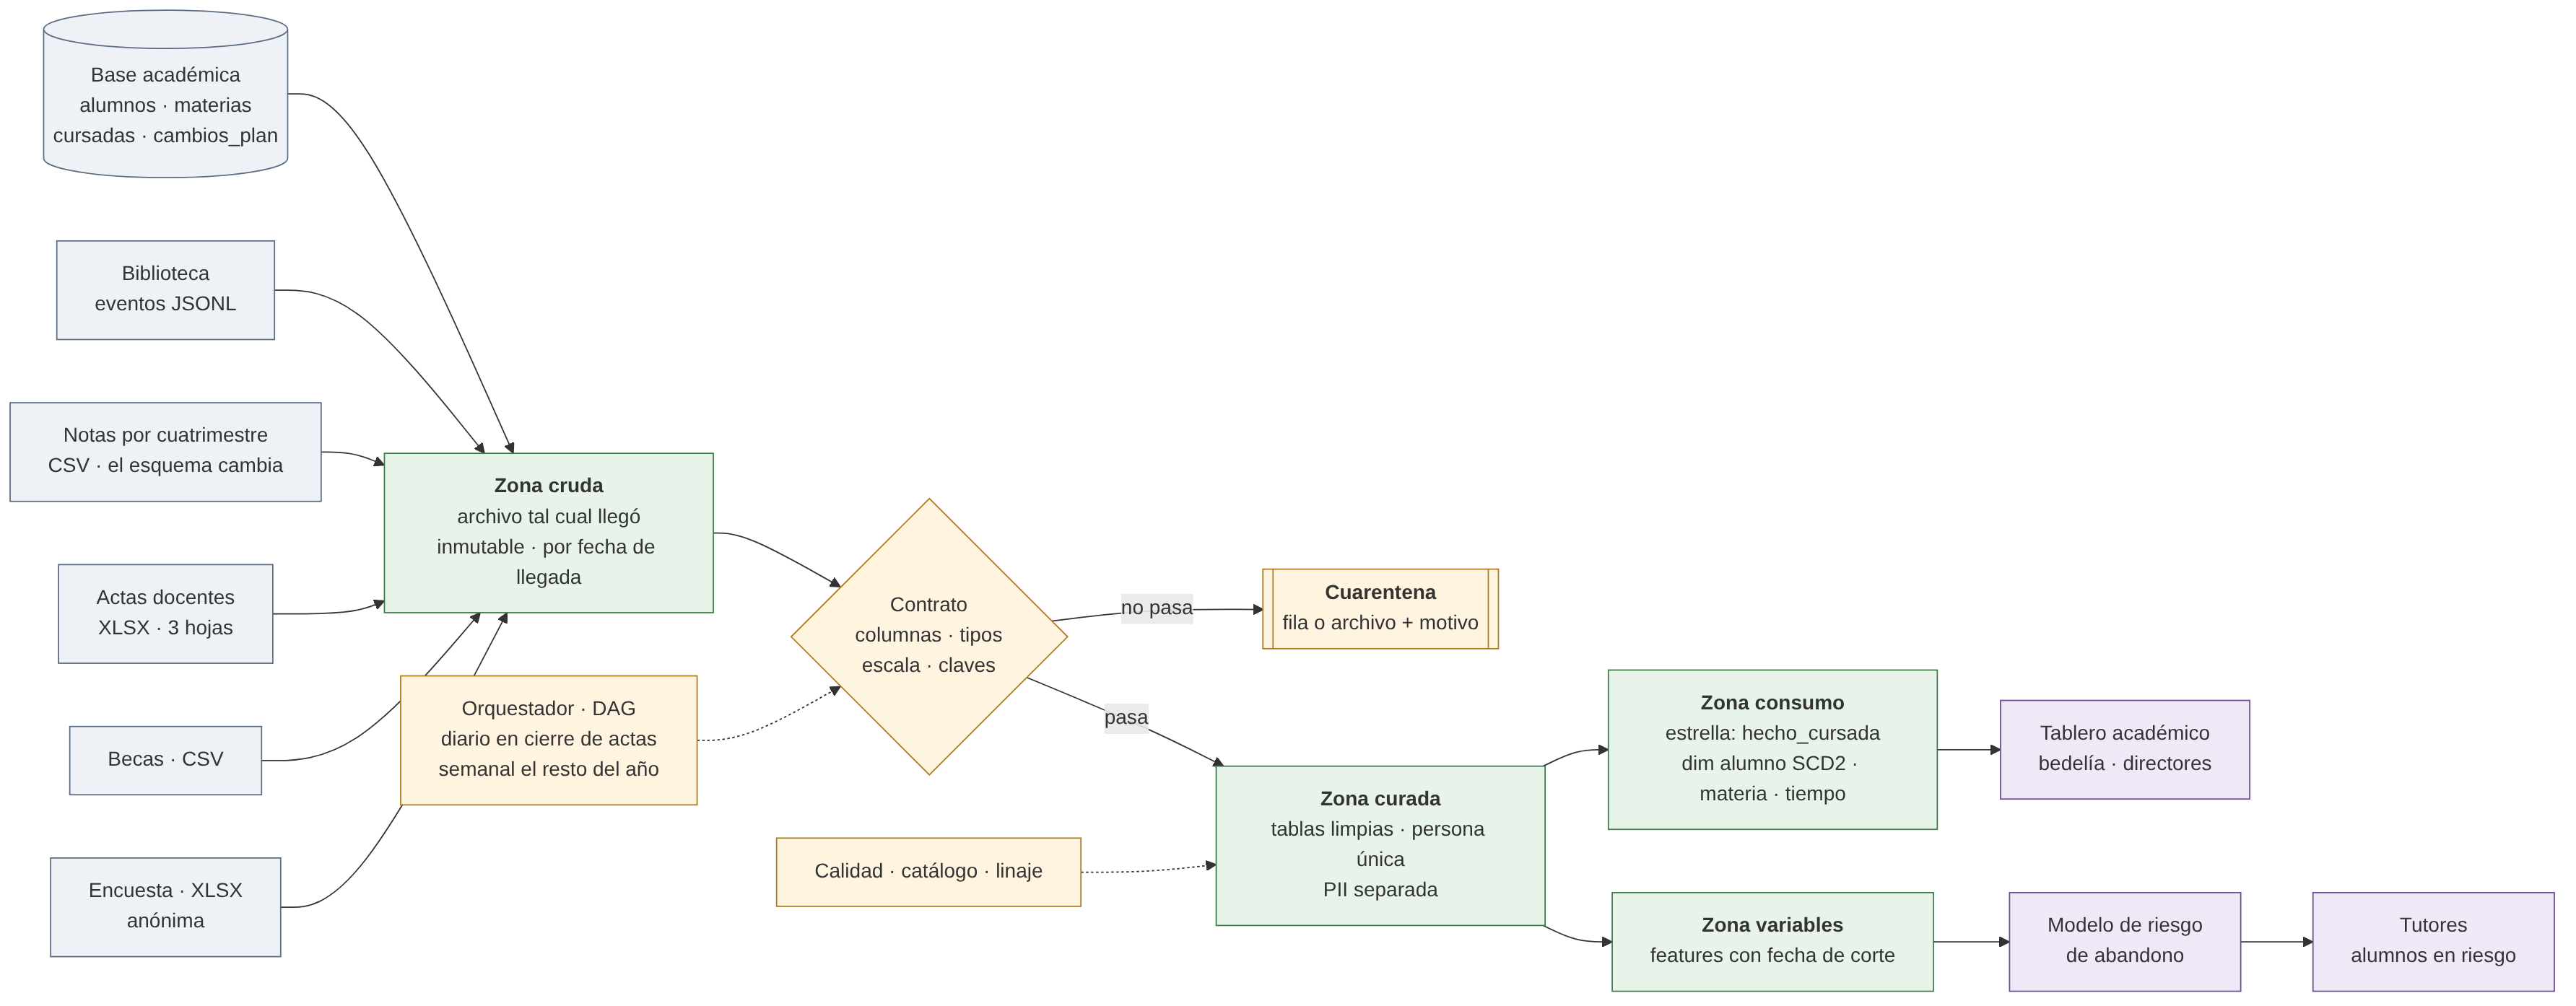

*El código fuente del diagrama está en `img/arquitectura.mmd` (Mermaid), por si hay que editarlo.*

**Cómo se lee.** Todo lo que llega, propio o externo, se guarda primero **tal cual** en la zona cruda. Después pasa por un contrato que revisa columnas, tipos, escala y claves. Lo que pasa el contrato va a la zona curada. Lo que no pasa va a cuarentena con su motivo, y no se pierde ni se arregla a ciegas. Desde la zona curada salen dos caminos:
- **consumo:** el modelo estrella, para los tableros;
- **variables:** las variables del modelo de abandono, calculadas con una fecha de corte para no usar información del futuro.

| Campo | Contenido |
| --- | --- |
| Decisión | Dónde y en qué forma se guardan los datos: **lakehouse liviano**. La zona cruda guarda archivos, y las zonas curada, variables y consumo son tablas SQL con esquema (SQLite en este trabajo). |
| Restricción comprobable | 1) Los archivos externos cambian de formato sin aviso (en el diagnóstico: columnas renombradas y escala 0–100 en 2025-1c). 2) Hay que poder **reprocesar** cuando cambia una regla, por ejemplo cómo se resuelven los dos legajos. 3) El volumen es chico: 2.060 alumnos, 15.315 cursadas, 10.946 préstamos y unos 2,5 MB en total. 4) Hace falta un modelo dimensional con historia (SCD 2) y variables para Machine Learning. |
| Opción elegida y costo que se acepta | Lakehouse liviano. El costo es tener dos formas de almacenamiento (archivos y tablas), y que el catálogo tiene que mantenerlas alineadas. También se guarda más, porque los crudos no se borran, pero con unos 2,5 MB en total eso es despreciable. |
| **Alternativa descartada y por qué** | **Data warehouse clásico con ETL**, que transforma antes de guardar y solo guarda el resultado limpio. Se descarta porque, cuando un archivo cambia de formato, el original se pierde. Sin el original no hay reproceso ni evidencia de qué llegó. **También se descarta un lakehouse con Spark y Delta Lake:** resuelve un volumen que no tenemos y suma un clúster que el caso no justifica. |
| Control que detecta el fallo y qué se hace cuando suena | **Balance de filas por lote:** filas leídas en cruda = filas cargadas en curada + filas en cuarentena. Se registra en `control_lote`. Si no cierra, el lote queda en estado «falló», no se publica en consumo y el tablero sigue mostrando el último lote bueno. Decide la **responsable de datos académicos** (rol de gobierno, módulo 6): reprocesa, o libera el lote con una nota. |

**Qué cambiaría la decisión.**
- Si el volumen se multiplicara por cien (por ejemplo, eventos de un campus virtual por clic), la zona cruda pasaría a Parquet particionado, y el procesamiento a Spark o DuckDB.
- Si se necesitaran alertas de abandono en minutos en vez de días, haría falta ingestión por eventos (streaming).

Hoy ninguno de los dos aplica: el calendario es diario como máximo.

## 2 · Modelado

### Modelo conceptual: qué cosas existen y cómo se relacionan

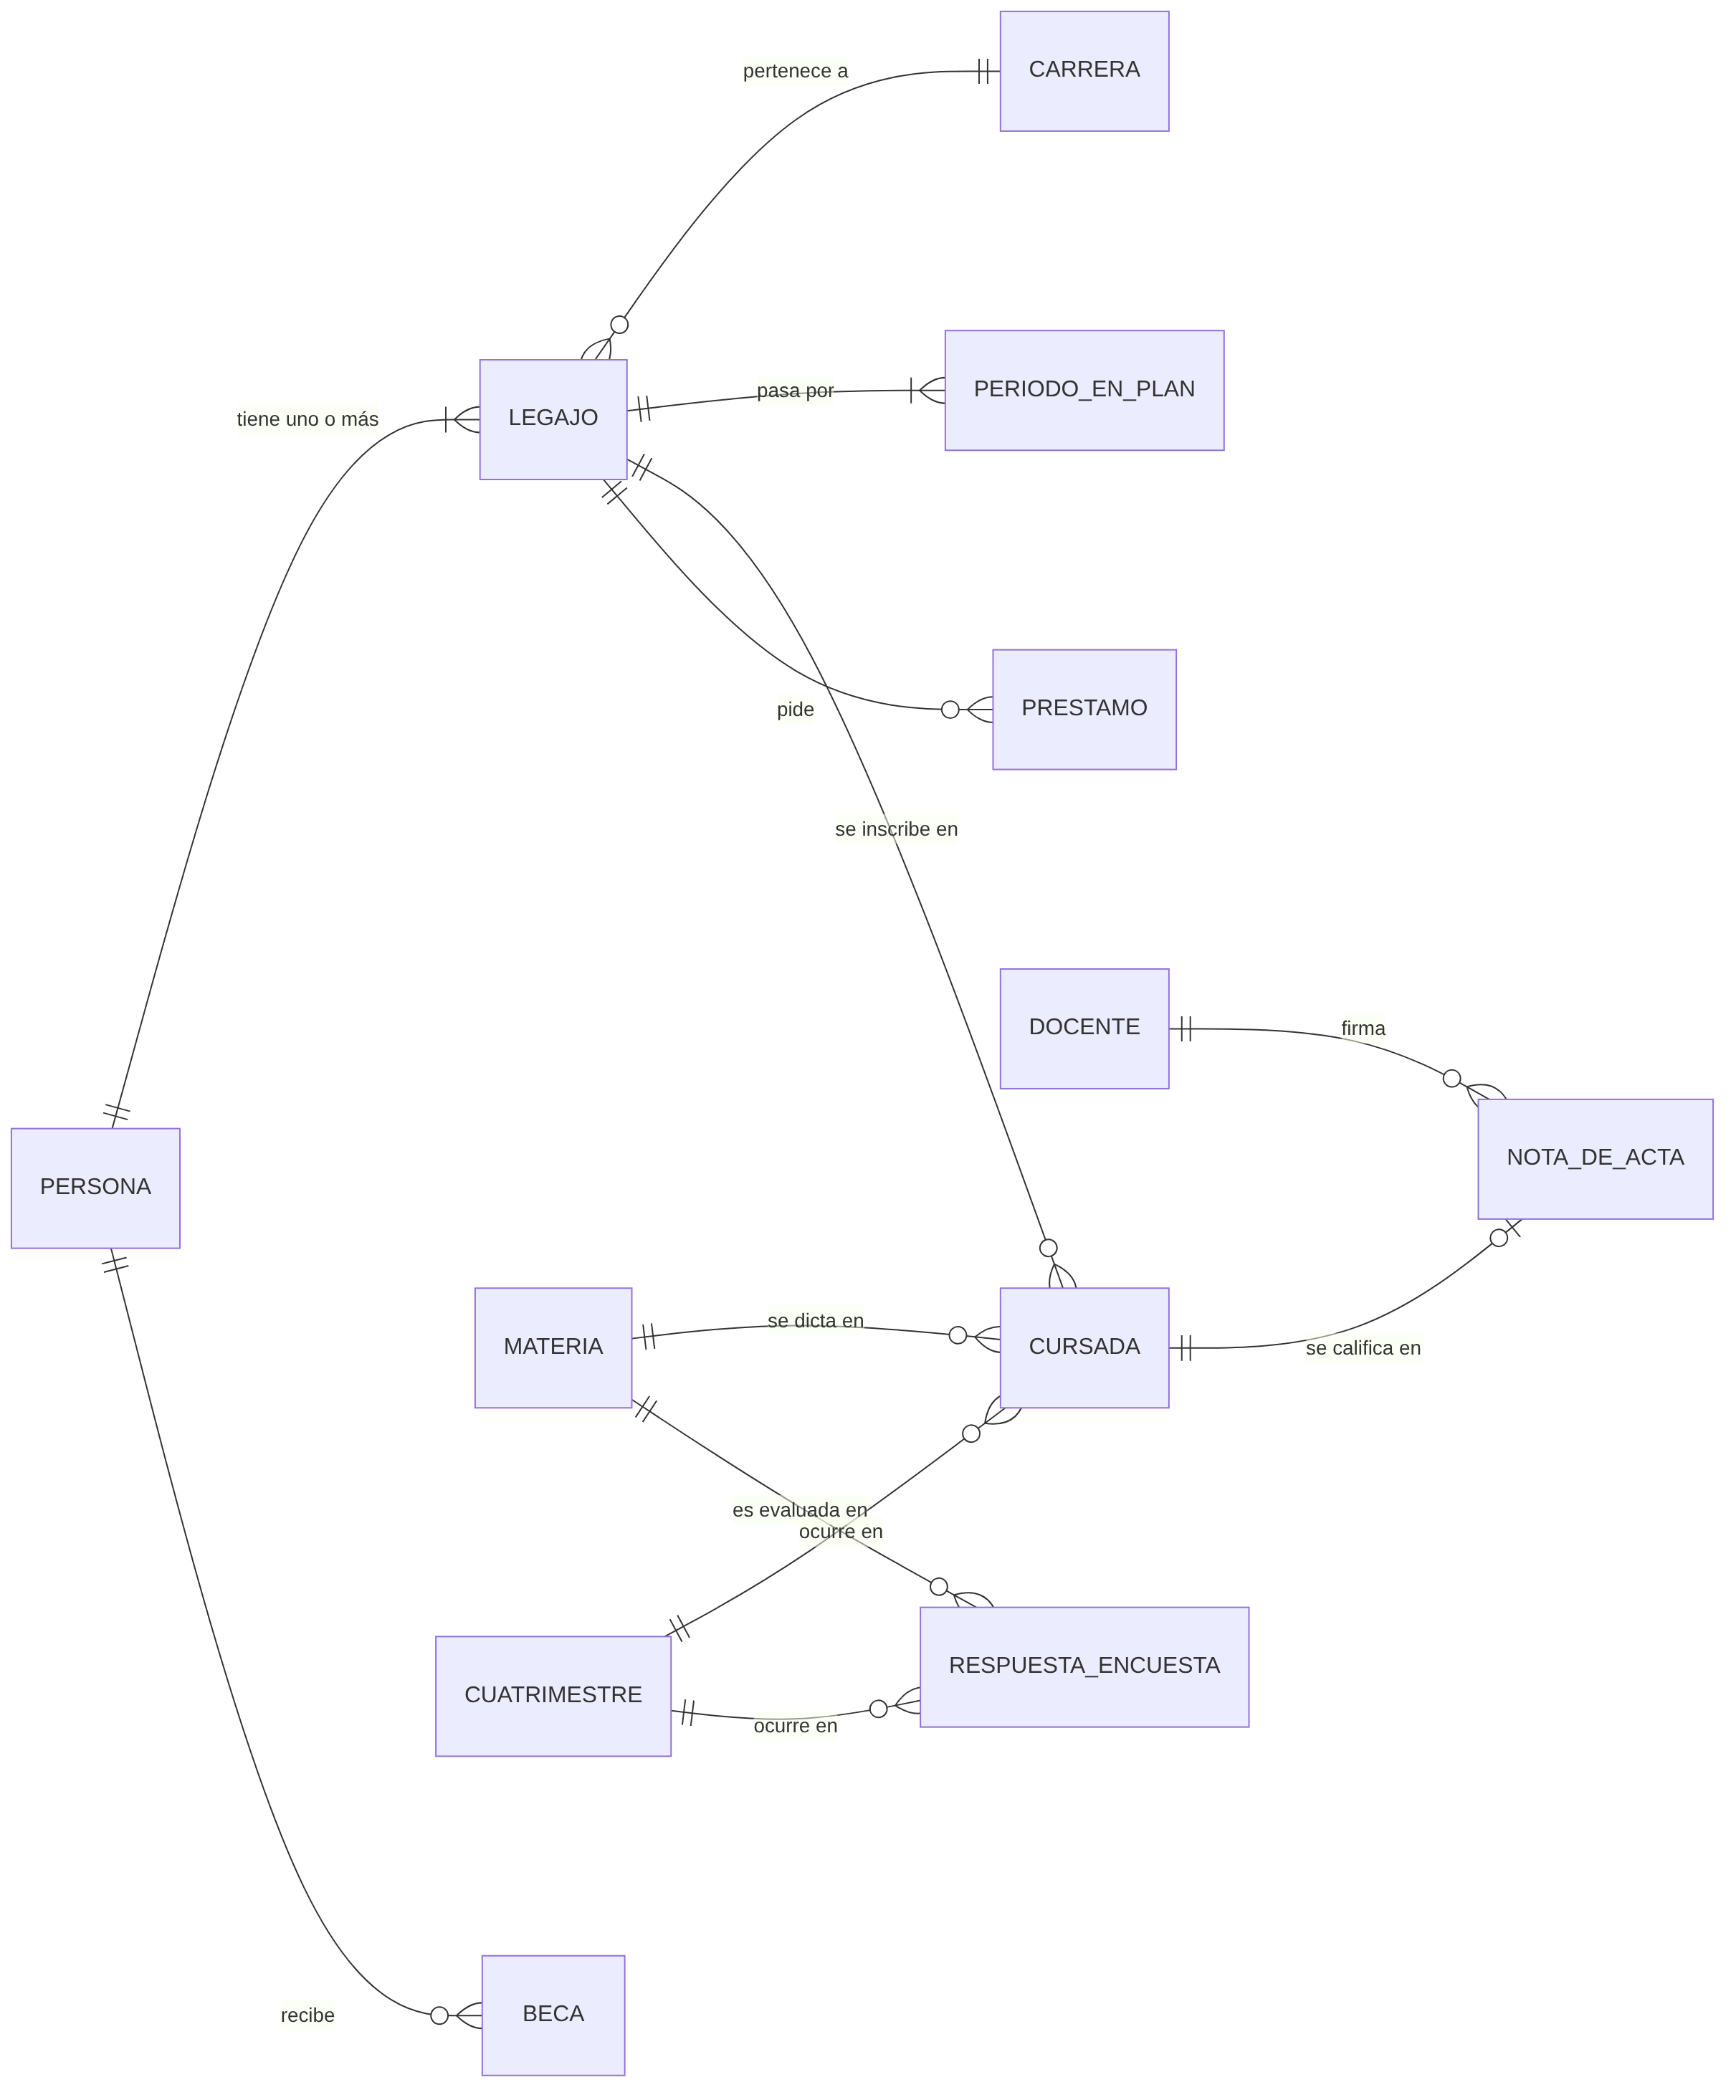

**La decisión central está en la primera relación: una persona tiene uno o más legajos.** El diagnóstico mostró 60 personas con dos legajos. Si el modelo tratara al legajo como si fuera la persona, esas 60 personas contarían dos veces en cualquier indicador. Y el modelo de abandono vería a un alumno «nuevo» sin historia.

### Modelo lógico: entidades, claves y atributos (sin pensar en el motor)

| Entidad | Clave | Atributos | Se relaciona con |
| --- | --- | --- | --- |
| Persona | id_persona | DNI, nombre, fecha de nacimiento, correo | Legajo (1 a N), Beca (1 a N) |
| Legajo | legajo | id_alumno, carrera, es_vigente | Persona (N a 1), Cursada (1 a N), Préstamo (1 a N) |
| Período en plan | persona + válido_desde | plan, válido_hasta | Persona (N a 1). En el físico son las versiones de `dim_alumno` |
| Materia | id_materia | nombre, carrera | Cursada (1 a N), Respuesta de encuesta (1 a N) |
| Cuatrimestre | cuatrimestre | año, número, fecha de inicio, fecha de fin | Cursada (1 a N) |
| Cursada | id_cursada | estado | Legajo, Materia, Cuatrimestre; Nota de acta (1 a 0 o 1) |
| Nota de acta | id_cursada | nota, ausente, docente, condición, fuente | Cursada (1 a 1) |
| Préstamo | persona + ISBN + fecha y hora | — | Persona (N a 1) |
| Beca | persona + desde | tipo, porcentaje | Persona (N a 1) |
| Respuesta de encuesta | id_respuesta | puntaje, comentario | Materia, Cuatrimestre (sin persona: es anónima) |

### Modelo dimensional: el hecho de cursada y nota

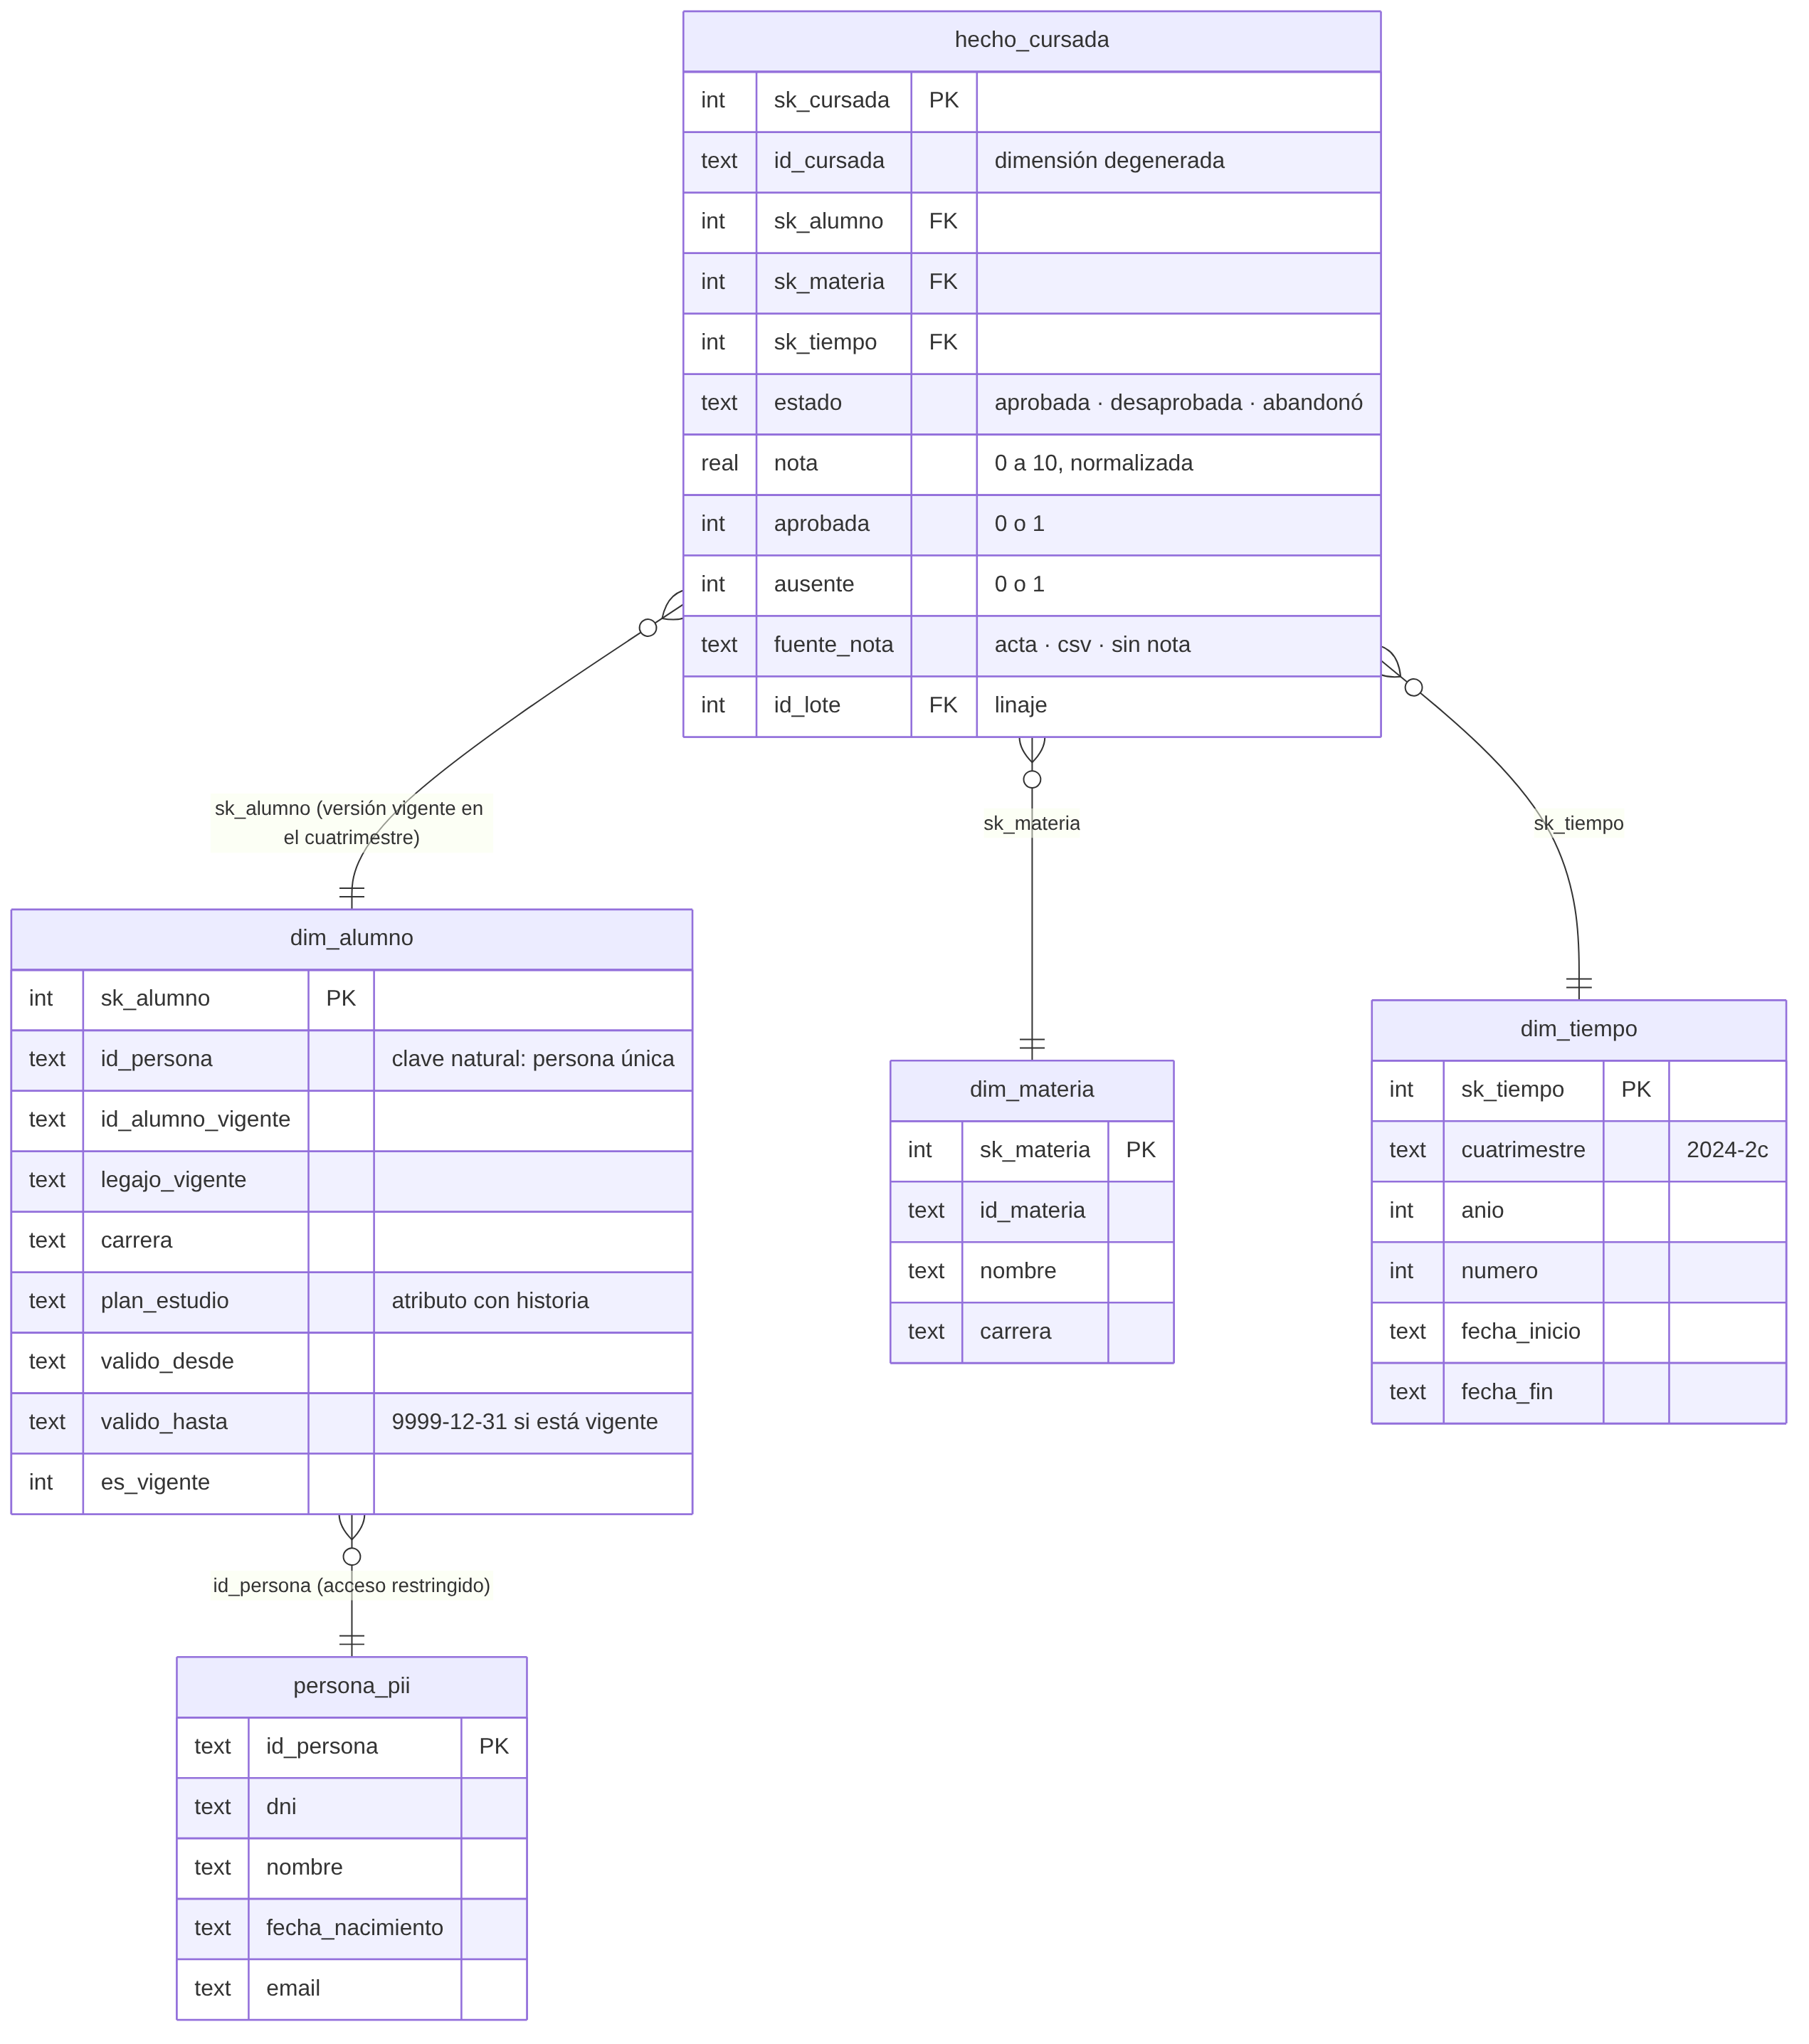

- **Grano del hecho:** una fila por **persona × materia × cuatrimestre**. Es la pregunta de negocio: cómo le fue a esta persona en esta materia este cuatrimestre.
- **Medidas:** `nota` (normalizada de 0 a 10), `aprobada` (0 o 1, para sumar y sacar tasas) y `ausente` (0 o 1).
- **Atributos de control:** `fuente_nota` (acta, CSV o sin nota) y `id_lote` (de qué carga vino la fila, para el linaje).
- **`dim_alumno` guarda historia (SCD tipo 2).** Cada cambio de plan cierra la versión anterior (`valido_hasta`) y abre una nueva. La cursada apunta a **la versión vigente al inicio del cuatrimestre**, que es el momento de la inscripción. Así, «tasa de aprobación por plan» cuenta a cada alumno en el plan en el que realmente cursó.
- **Los datos personales no están en la dimensión.** Viven en `persona_pii`, una tabla aparte con acceso restringido (módulo 9). Quien arma un tablero no necesita el DNI para contar aprobados.

| Campo | Decisión 1: grano y SCD 2 | Decisión 2: datos personales separados |
| --- | --- | --- |
| Restricción comprobable | 60 personas con dos legajos; 300 alumnos cambiaron de plan durante 2025-1c, y la base solo guarda el plan actual. | El caso marca como sensibles DNI, nombre, fecha de nacimiento, correo y legajo. |
| Opción elegida y costo que se acepta | Grano persona × materia × cuatrimestre, con `dim_alumno` en SCD 2. Costo: la carga tiene que buscar la versión vigente por fecha, y la dimensión crece con cada cambio. | Tabla `persona_pii` separada, unida por `id_persona`. Costo: un join más para quien sí está autorizado a ver datos personales. |
| **Alternativa descartada y por qué** | **SCD tipo 1** (pisar el plan). Se pierde en qué plan cursó cada alumno, y el indicador por plan queda mal para los 300 que cambiaron. **Grano por legajo:** cuenta dos veces a 60 personas. | **Enmascarar las columnas dentro de `dim_alumno`.** Todos los que leen la dimensión quedan a un permiso mal dado de ver el DNI. Separar la tabla vuelve el control más simple: se da o no se da acceso a una tabla. |
| Control que detecta el fallo y qué se hace cuando suena | Restricciones en el motor: única por grano, una sola versión vigente por persona y fechas coherentes (ver las pruebas abajo). Si una carga las viola, la transacción se revierte entera y el lote queda en «falló». | Ninguna tabla de consumo tiene columnas de datos personales: hay una prueba que lo verifica sobre el DDL. |

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S8 | El primer cuatrimestre va del 1/3 al 31/7 y el segundo del 1/8 al 31/12. | Los préstamos arrancan el 1/8/2024, las becas rigen desde el 1/3/2025 y los cambios de plan caen entre marzo y junio. |
| S9 | Una cursada pertenece a la versión del alumno vigente al inicio del cuatrimestre. | El alumno se inscribe con el plan que tiene en ese momento. Los cambios de plan ocurren a mitad del cuatrimestre. |

### Modelo físico: el DDL

La celda siguiente crea el almacén (`dwh.db`) con cuatro grupos de tablas:
- **control:** lotes y cuarentena;
- **zona curada:** tablas limpias del dominio;
- **zona consumo:** el modelo estrella;
- **variables:** se arma en el módulo 7.

Se puede correr de nuevo sin problema, porque borra y vuelve a crear las tablas.

En el físico, `cursada` y `prestamo` ya apuntan a la persona: la traducción de legajo a persona se hace al pasar a la zona curada.

In [6]:
DDL = """
PRAGMA foreign_keys = ON;

-- Se borra en orden inverso a las dependencias, para poder correr la celda las veces que haga falta.
DROP TABLE IF EXISTS hecho_cursada;
DROP TABLE IF EXISTS dim_alumno;
DROP TABLE IF EXISTS dim_materia;
DROP TABLE IF EXISTS dim_tiempo;
DROP TABLE IF EXISTS respuesta_encuesta;
DROP TABLE IF EXISTS beca;
DROP TABLE IF EXISTS prestamo;
DROP TABLE IF EXISTS nota;
DROP TABLE IF EXISTS cursada;
DROP TABLE IF EXISTS legajo;
DROP TABLE IF EXISTS persona_pii;
DROP TABLE IF EXISTS materia;
DROP TABLE IF EXISTS cuarentena;
DROP TABLE IF EXISTS control_lote;

-- ============ CONTROL: de dónde vino cada fila y qué quedó afuera ============
CREATE TABLE control_lote (
    id_lote           INTEGER PRIMARY KEY,
    proceso           TEXT NOT NULL,                 -- p. ej. 'ingesta_notas', 'carga_dim_alumno'
    fuente            TEXT NOT NULL,                 -- p. ej. 'notas_2025-1c.csv'
    inicio            TEXT NOT NULL,
    fin               TEXT,
    filas_leidas      INTEGER,
    filas_cargadas    INTEGER,
    filas_cuarentena  INTEGER,
    huella            TEXT,                          -- SHA-256 del archivo: si ya se ingirió igual, no se reprocesa
    estado            TEXT NOT NULL CHECK (estado IN ('en curso', 'ok', 'falló', 'omitido')),
    detalle           TEXT                           -- qué pasó, sobre todo cuando falla
);

CREATE TABLE cuarentena (
    id_cuarentena  INTEGER PRIMARY KEY,
    id_lote        INTEGER NOT NULL REFERENCES control_lote (id_lote),
    fuente         TEXT NOT NULL,
    registro       TEXT NOT NULL,                    -- la fila original, en JSON, tal como llegó
    motivo         TEXT NOT NULL,                    -- p. ej. 'nota fuera de rango', 'alumno inexistente'
    resuelto       INTEGER NOT NULL DEFAULT 0 CHECK (resuelto IN (0, 1))
);

-- ============ ZONA CURADA: el dominio limpio ============
CREATE TABLE persona_pii (                           -- acceso restringido (módulo 9)
    id_persona        TEXT PRIMARY KEY,
    dni               TEXT NOT NULL UNIQUE CHECK (length(dni) = 8 AND dni NOT GLOB '*[^0-9]*'),
    nombre            TEXT NOT NULL,
    fecha_nacimiento  TEXT NOT NULL CHECK (date(fecha_nacimiento) IS NOT NULL),
    email             TEXT NOT NULL CHECK (email LIKE '%_@_%')
);

CREATE TABLE legajo (                                -- equivalencias: una persona, uno o más legajos
    legajo      TEXT PRIMARY KEY CHECK (legajo GLOB 'L[0-9][0-9][0-9][0-9][0-9]'),
    id_alumno   TEXT NOT NULL UNIQUE,
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    carrera     TEXT NOT NULL,
    es_vigente  INTEGER NOT NULL CHECK (es_vigente IN (0, 1))
);
CREATE UNIQUE INDEX ux_legajo_un_vigente ON legajo (id_persona) WHERE es_vigente = 1;

CREATE TABLE materia (
    id_materia  TEXT PRIMARY KEY,
    nombre      TEXT NOT NULL UNIQUE,
    carrera     TEXT NOT NULL
);

CREATE TABLE cursada (
    id_cursada    TEXT PRIMARY KEY,
    id_persona    TEXT NOT NULL REFERENCES persona_pii (id_persona),
    id_materia    TEXT NOT NULL REFERENCES materia (id_materia),
    cuatrimestre  TEXT NOT NULL CHECK (cuatrimestre GLOB '[0-9][0-9][0-9][0-9]-[12]c'),
    estado        TEXT NOT NULL CHECK (estado IN ('aprobada', 'desaprobada', 'abandonó')),
    UNIQUE (id_persona, id_materia, cuatrimestre)
);

CREATE TABLE nota (                                  -- una nota por cursada, ya normalizada de 0 a 10
    id_cursada   TEXT PRIMARY KEY REFERENCES cursada (id_cursada),
    nota         REAL CHECK (nota IS NULL OR nota BETWEEN 0 AND 10),
    ausente      INTEGER NOT NULL DEFAULT 0 CHECK (ausente IN (0, 1)),
    docente      TEXT,
    condicion    TEXT CHECK (condicion IS NULL OR condicion IN ('Regular', 'Libre')),
    fuente_nota  TEXT NOT NULL CHECK (fuente_nota IN ('acta', 'csv')),
    id_lote      INTEGER REFERENCES control_lote (id_lote),
    CHECK (NOT (ausente = 1 AND nota IS NOT NULL))   -- un ausente no tiene nota
);

CREATE TABLE prestamo (
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    isbn        TEXT NOT NULL CHECK (length(isbn) = 13),
    ts          TEXT NOT NULL CHECK (datetime(ts) IS NOT NULL),
    id_lote     INTEGER REFERENCES control_lote (id_lote),
    PRIMARY KEY (id_persona, isbn, ts)               -- clave natural: reprocesar no duplica
);

CREATE TABLE beca (
    id_persona  TEXT NOT NULL REFERENCES persona_pii (id_persona),
    tipo_beca   TEXT NOT NULL,
    porcentaje  INTEGER NOT NULL CHECK (porcentaje BETWEEN 1 AND 100),
    desde       TEXT NOT NULL CHECK (date(desde) IS NOT NULL),
    PRIMARY KEY (id_persona, desde)
);

CREATE TABLE respuesta_encuesta (                    -- anónima: no tiene ninguna columna de persona
    id_respuesta  INTEGER PRIMARY KEY,
    id_materia    TEXT NOT NULL REFERENCES materia (id_materia),
    cuatrimestre  TEXT NOT NULL,
    puntaje       INTEGER NOT NULL CHECK (puntaje BETWEEN 1 AND 5),
    comentario    TEXT
);

-- ============ ZONA CONSUMO: el modelo estrella ============
CREATE TABLE dim_tiempo (
    sk_tiempo     INTEGER PRIMARY KEY,
    cuatrimestre  TEXT NOT NULL UNIQUE,
    anio          INTEGER NOT NULL,
    numero        INTEGER NOT NULL CHECK (numero IN (1, 2)),
    fecha_inicio  TEXT NOT NULL,
    fecha_fin     TEXT NOT NULL,
    CHECK (fecha_inicio < fecha_fin)
);

CREATE TABLE dim_materia (
    sk_materia  INTEGER PRIMARY KEY,
    id_materia  TEXT NOT NULL UNIQUE,
    nombre      TEXT NOT NULL,
    carrera     TEXT NOT NULL
);

CREATE TABLE dim_alumno (                            -- SCD tipo 2: una fila por versión
    sk_alumno         INTEGER PRIMARY KEY,
    id_persona        TEXT NOT NULL,                 -- clave natural (sin datos personales)
    id_alumno_vigente TEXT NOT NULL,
    legajo_vigente    TEXT NOT NULL,
    carrera           TEXT NOT NULL,
    plan_estudio      TEXT NOT NULL,
    valido_desde      TEXT NOT NULL,
    valido_hasta      TEXT NOT NULL DEFAULT '9999-12-31',
    es_vigente        INTEGER NOT NULL CHECK (es_vigente IN (0, 1)),
    UNIQUE (id_persona, valido_desde),
    CHECK (valido_desde < valido_hasta),
    CHECK ((es_vigente = 1) = (valido_hasta = '9999-12-31'))
);
CREATE UNIQUE INDEX ux_dim_alumno_un_vigente ON dim_alumno (id_persona) WHERE es_vigente = 1;

CREATE TABLE hecho_cursada (                         -- grano: persona × materia × cuatrimestre
    sk_cursada   INTEGER PRIMARY KEY,
    id_cursada   TEXT NOT NULL UNIQUE,               -- dimensión degenerada
    sk_alumno    INTEGER NOT NULL REFERENCES dim_alumno (sk_alumno),
    sk_materia   INTEGER NOT NULL REFERENCES dim_materia (sk_materia),
    sk_tiempo    INTEGER NOT NULL REFERENCES dim_tiempo (sk_tiempo),
    estado       TEXT NOT NULL CHECK (estado IN ('aprobada', 'desaprobada', 'abandonó')),
    nota         REAL CHECK (nota IS NULL OR nota BETWEEN 0 AND 10),
    aprobada     INTEGER NOT NULL CHECK (aprobada IN (0, 1)),
    ausente      INTEGER NOT NULL CHECK (ausente IN (0, 1)),
    fuente_nota  TEXT NOT NULL CHECK (fuente_nota IN ('acta', 'csv', 'sin nota')),
    id_lote      INTEGER REFERENCES control_lote (id_lote),
    UNIQUE (sk_alumno, sk_materia, sk_tiempo)
);
CREATE INDEX ix_hecho_tiempo  ON hecho_cursada (sk_tiempo);
CREATE INDEX ix_hecho_materia ON hecho_cursada (sk_materia);
"""

almacen = dwh()
almacen.executescript(DDL)
almacen.execute("PRAGMA foreign_keys = ON")

zona = {"control": ["control_lote", "cuarentena"],
        "curada": ["persona_pii", "legajo", "materia", "cursada", "nota", "prestamo", "beca", "respuesta_encuesta"],
        "consumo": ["dim_tiempo", "dim_materia", "dim_alumno", "hecho_cursada"]}
tablas = sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", base="dwh.db").name.tolist()
pd.DataFrame([{"zona": z, "tabla": t, "creada": t in tablas} for z, ts in zona.items() for t in ts])

,zona,tabla,creada
0,control,control_lote,True
1,control,cuarentena,True
2,curada,persona_pii,True
3,curada,legajo,True
4,curada,materia,True
5,curada,cursada,True
6,curada,nota,True
7,curada,prestamo,True
8,curada,beca,True
9,curada,respuesta_encuesta,True


### Pruebas del modelo físico

Un modelo es verificable si **rechaza los casos difíciles** que encontramos en el diagnóstico. Cada prueba intenta meter un dato malo y espera que el motor lo rechace. Las pruebas corren dentro de una transacción que después se revierte, así que el almacén queda vacío para la carga del módulo 3.

In [7]:
# Pruebas del modelo físico: cada restricción tiene que rechazar el caso difícil que encontramos en el diagnóstico.
# Todo corre dentro de una transacción que al final se revierte: el almacén queda vacío.
def debe_fallar(nombre, sentencia):
    try:
        almacen.execute(sentencia)
        return {"prueba": nombre, "resultado": "✘ lo aceptó (la restricción no funciona)", "motivo": ""}
    except sqlite3.IntegrityError as error:
        return {"prueba": nombre, "resultado": "✔ rechazado", "motivo": str(error)}

almacen.execute("SAVEPOINT pruebas")
# Filas válidas de base (un alumno que cambió de plan en 2025, con una cursada), para probar contra ellas.
for s in ["INSERT INTO dim_tiempo  VALUES (1, '2024-2c', 2024, 2, '2024-08-01', '2024-12-31')",
          "INSERT INTO dim_materia VALUES (1, 'MT000', 'Materia 00', 'Diseño')",
          "INSERT INTO dim_alumno  VALUES (1, 'P00771', 'AL00771', 'L20771', 'Administración', '2018', '2024-08-01', '2025-04-15', 0)",
          "INSERT INTO dim_alumno  VALUES (2, 'P00771', 'AL00771', 'L20771', 'Administración', '2023', '2025-04-15', '9999-12-31', 1)",
          "INSERT INTO hecho_cursada VALUES (1, 'CU000001', 1, 1, 1, 'aprobada', 7.0, 1, 0, 'acta', NULL)",
          "INSERT INTO persona_pii VALUES ('P00771', '20442824', 'Alumno 00771', '2003-01-04', 'alumno771@uniandina.test')"]:
    almacen.execute(s)

pruebas = pd.DataFrame([
    debe_fallar("Nota fuera de rango (12, como en notas_2024-2c)",
                "INSERT INTO hecho_cursada VALUES (2, 'CU000002', 2, 1, 1, 'aprobada', 12, 1, 0, 'csv', NULL)"),
    debe_fallar("Nota sin normalizar (escala 0–100 de 2025-1c)",
                "INSERT INTO nota VALUES ('CU000001', 80, 0, 'DOC09', 'Regular', 'csv', NULL)"),
    debe_fallar("Misma persona, materia y cuatrimestre dos veces (duplicado)",
                "INSERT INTO hecho_cursada VALUES (3, 'CU999999', 1, 1, 1, 'aprobada', 7.0, 1, 0, 'csv', NULL)"),
    debe_fallar("Cursada de un alumno que no existe (los AL9xxxx)",
                "INSERT INTO hecho_cursada VALUES (4, 'CX00000', 99, 1, 1, 'aprobada', 7.0, 1, 0, 'csv', NULL)"),
    debe_fallar("Dos versiones vigentes de la misma persona",
                "INSERT INTO dim_alumno VALUES (3, 'P00771', 'AL02013', 'L30013', 'Administración', '2023', '2025-05-01', '9999-12-31', 1)"),
    debe_fallar("Versión con fechas al revés",
                "INSERT INTO dim_alumno VALUES (4, 'P00999', 'AL00999', 'L20999', 'Derecho', '2018', '2025-06-01', '2025-01-01', 0)"),
    debe_fallar("Versión marcada vigente pero con fecha de cierre",
                "INSERT INTO dim_alumno VALUES (5, 'P00998', 'AL00998', 'L20998', 'Derecho', '2018', '2024-08-01', '2025-01-01', 1)"),
    debe_fallar("Mismo DNI para dos personas (los legajos duplicados)",
                "INSERT INTO persona_pii VALUES ('P02013', '20442824', 'Alumno 00771', '2003-01-04', 'alumno771@uniandina.test')"),
    debe_fallar("DNI con puntos (como llega en becas.csv)",
                "INSERT INTO persona_pii VALUES ('P00001', '35.527.738', 'X', '2000-01-01', 'x@uniandina.test')"),
    debe_fallar("Legajo sin la «L» (como llega en las actas)",
                "INSERT INTO legajo VALUES ('21464', 'AL01464', 'P00771', 'Derecho', 0)"),
    debe_fallar("Ausente con nota",
                "INSERT INTO nota VALUES ('CU000001', 7, 1, 'DOC09', 'Regular', 'acta', NULL)"),
    debe_fallar("Puntaje de encuesta fuera de 1 a 5",
                "INSERT INTO respuesta_encuesta VALUES (1, 'MT000', '2024-2c', 10, NULL)"),
])
almacen.execute("ROLLBACK TO pruebas"); almacen.execute("RELEASE pruebas")

# Y una prueba sobre el propio DDL: ninguna tabla de consumo tiene columnas de datos personales.
PII = {"dni", "nombre", "fecha_nacimiento", "email"}
columnas_consumo = {t: set(sql(f"PRAGMA table_info({t})", base="dwh.db").name) for t in zona["consumo"]}
fugas = {t: sorted(c & PII) for t, c in columnas_consumo.items() if (c & PII) - ({"nombre"} if t == "dim_materia" else set())}
print("✔ Ninguna tabla de consumo tiene datos personales." if not fugas else f"✘ Datos personales en consumo: {fugas}")
print(f"{(pruebas.resultado.str.startswith('✔')).sum()} de {len(pruebas)} restricciones rechazaron el caso difícil.")
pruebas

✔ Ninguna tabla de consumo tiene datos personales.
12 de 12 restricciones rechazaron el caso difícil.


,prueba,resultado,motivo
0,"Nota fuera de rango (12, como en notas_2024-2c)",✔ rechazado,CHECK constraint failed: nota IS NULL OR nota ...
1,Nota sin normalizar (escala 0–100 de 2025-1c),✔ rechazado,CHECK constraint failed: nota IS NULL OR nota ...
2,"Misma persona, materia y cuatrimestre dos vece...",✔ rechazado,UNIQUE constraint failed: hecho_cursada.sk_alu...
3,Cursada de un alumno que no existe (los AL9xxxx),✔ rechazado,FOREIGN KEY constraint failed
4,Dos versiones vigentes de la misma persona,✔ rechazado,UNIQUE constraint failed: dim_alumno.id_persona
5,Versión con fechas al revés,✔ rechazado,CHECK constraint failed: valido_desde < valido...
6,Versión marcada vigente pero con fecha de cierre,✔ rechazado,CHECK constraint failed: (es_vigente = 1) = (v...
7,Mismo DNI para dos personas (los legajos dupli...,✔ rechazado,UNIQUE constraint failed: persona_pii.dni
8,DNI con puntos (como llega en becas.csv),✔ rechazado,CHECK constraint failed: length(dni) = 8 AND d...
9,Legajo sin la «L» (como llega en las actas),✔ rechazado,CHECK constraint failed: legajo GLOB 'L[0-9][0...


## 3 · PL/SQL

Un procedimiento que carga la dimensión alumno con historia (SCD tipo 2) y resuelve los alumnos duplicados. SQLite no tiene PL/SQL, así que cada paso es una sentencia SQL ejecutada desde una función de Python, dentro de una transacción.

**Qué hace `cargar_dim_alumno(corte)`, paso a paso:**

1. **Resuelve a la persona.** Agrupa los legajos por DNI y elige como vigente al que tiene más cursadas. La persona toma su identificador (`P01109`) del legajo vigente.
2. **Controla la identidad.** Un mismo DNI con otro nombre u otra fecha de nacimiento **no se fusiona**: va a cuarentena. Unir a dos personas distintas es peor que dejar un duplicado.
3. **Da de alta o actualiza** la persona (con sus datos personales, en `persona_pii`) y sus legajos. Si ya existen, no los duplica.
4. **Une los cambios de plan por persona**, aunque vengan por el legajo duplicado. Encontramos una persona con el mismo cambio cargado en sus dos legajos, en fechas distintas: vale el primero y el otro queda registrado en cuarentena.
5. **Arma la foto de cada persona a la fecha de corte**, con el plan que tenía ese día.
6. **Compara la foto con la versión vigente.** Si algo cambió, cierra la versión vigente con la fecha del cambio y abre una nueva. Si la persona no existía, la da de alta.
7. **Controla antes y después.**
   - Antes: un cambio no puede tener fecha anterior a la versión vigente.
   - Después: tiene que haber exactamente una versión vigente por persona y ninguna versión puede pisarse con otra.
   - Si un control no pasa, se revierte **toda** la transacción y el lote queda en `control_lote` como «falló», con el motivo.

| Campo | Contenido |
| --- | --- |
| Decisión | Carga **incremental** de la SCD 2, por conjuntos (estilo MERGE), con transacción y controles antes y después. |
| Restricción comprobable | La base académica **pisa** el plan (`alumnos.plan_estudio` ya tiene el nuevo). La historia solo existe porque comparamos con lo que ya cargamos. Además, 60 personas tienen dos legajos, y una tiene el mismo cambio de plan registrado dos veces. |
| Opción elegida y costo que se acepta | Incremental: cada corrida compara con la versión vigente. El costo es que **no se puede reprocesar hacia atrás**. Corregir el pasado obliga a reconstruir la dimensión desde la primera foto. |
| **Alternativa descartada y por qué** | **Reconstruir la dimensión desde cero en cada corrida** a partir de `cambios_plan`. Hoy funcionaría, pero depende de que esa tabla exista y esté completa. Si un cambio no queda registrado ahí, la historia se pierde sin que nadie lo note. El método incremental lo detecta igual, porque compara la foto con lo que ya está cargado. |
| Control que detecta el fallo y qué se hace cuando suena | Los controles del paso 7. Si suena, no se publica nada y el tablero sigue con la última carga buena. **Decide la responsable de datos académicos.** Si es un error de la fuente, se corrige ahí y se vuelve a correr. Si hace falta reprocesar hacia atrás, autoriza la reconstrucción completa. |

**Supuestos nuevos**

| # | Supuesto | Por qué |
| --- | --- | --- |
| S10 | El legajo vigente de una persona es el que tiene más cursadas. Si empatan, el más antiguo. | Los legajos L3xxxx no tienen ninguna cursada. El desempate tiene que ser determinístico para que la carga sea idempotente. |
| S11 | Un mismo DNI con otro nombre u otra fecha de nacimiento no se fusiona: va a cuarentena. | Un DNI mal tipeado uniría a dos personas distintas. Hoy no hay ningún caso, pero la regla queda. |
| S12 | Si el mismo cambio de plan figura en los dos legajos de una persona, vale el de fecha más temprana. | El plan cambió la primera vez. El segundo registro es una carga repetida. |

<details>
<summary><b>Cómo se vería en Oracle PL/SQL</b> (referencia, no se ejecuta acá)</summary>

```sql
CREATE OR REPLACE PROCEDURE cargar_dim_alumno (p_corte IN DATE) AS
    v_lote   NUMBER;
    v_atras  NUMBER;
    e_carga_rechazada EXCEPTION;
BEGIN
    v_lote := pkg_control.abrir_lote('carga_dim_alumno');          -- con PRAGMA AUTONOMOUS_TRANSACTION

    -- (staging: stg_alumno ya resuelto a persona y a la fecha de corte)
    SELECT COUNT(*) INTO v_atras
    FROM stg_alumno s JOIN dim_alumno d ON d.id_persona = s.id_persona AND d.es_vigente = 1
    WHERE d.plan_estudio <> s.plan_estudio AND NVL(s.fecha_cambio, p_corte) <= d.valido_desde;
    IF v_atras > 0 THEN RAISE e_carga_rechazada; END IF;

    -- Cerrar la versión vigente de los que cambiaron (el ON va por sk_alumno: Oracle no deja
    -- actualizar una columna que se usa en el ON, como es_vigente)
    MERGE INTO dim_alumno d
    USING (SELECT v.sk_alumno, NVL(s.fecha_cambio, p_corte) AS fecha_efectiva
           FROM stg_alumno s JOIN dim_alumno v ON v.id_persona = s.id_persona AND v.es_vigente = 1
           WHERE v.plan_estudio <> s.plan_estudio OR v.carrera <> s.carrera
              OR v.legajo_vigente <> s.legajo_vigente) c
       ON (d.sk_alumno = c.sk_alumno)
    WHEN MATCHED THEN UPDATE SET d.valido_hasta = c.fecha_efectiva, d.es_vigente = 0;

    -- Abrir la versión nueva de los que cambiaron y dar de alta a los nuevos
    INSERT INTO dim_alumno (sk_alumno, id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                            valido_desde, valido_hasta, es_vigente)
    SELECT seq_dim_alumno.NEXTVAL, s.id_persona, s.id_alumno_vigente, s.legajo_vigente, s.carrera, s.plan_estudio,
           CASE WHEN EXISTS (SELECT 1 FROM dim_alumno x WHERE x.id_persona = s.id_persona)
                THEN NVL(s.fecha_cambio, p_corte) ELSE DATE '2024-08-01' END,
           DATE '9999-12-31', 1
    FROM stg_alumno s
    WHERE NOT EXISTS (SELECT 1 FROM dim_alumno d WHERE d.id_persona = s.id_persona AND d.es_vigente = 1);

    COMMIT;
    pkg_control.cerrar_lote(v_lote, 'ok');
EXCEPTION
    WHEN e_carga_rechazada THEN
        ROLLBACK; pkg_control.cerrar_lote(v_lote, 'falló', 'cambio con fecha anterior a la versión vigente');
    WHEN OTHERS THEN
        ROLLBACK; pkg_control.cerrar_lote(v_lote, 'falló', SQLERRM); RAISE;
END;
```

En Oracle, la versión fila por fila sería un cursor `FOR r IN (SELECT ...) LOOP ... END LOOP`. Cada vuelta del cursor alterna entre PL/SQL y SQL, y eso cuesta todavía más que en SQLite. La versión optimizada usa `MERGE` o `BULK COLLECT` con `FORALL`.
</details>

In [8]:
# ===== Procedimiento de carga de la dimensión alumno (SCD tipo 2) =====
# SQLite no tiene PL/SQL: cada paso es SQL ejecutado desde Python, dentro de una transacción.
# Si algo falla, se revierte todo y el lote queda registrado como «falló» con el motivo.

INICIO_DATOS = "2024-08-01"     # supuesto S7
FIN_DE_LOS_TIEMPOS = "9999-12-31"

almacen.isolation_level = None  # las transacciones las manejamos a mano: BEGIN, COMMIT y ROLLBACK
almacen.execute("PRAGMA foreign_keys = ON")
if "op" not in [fila[1] for fila in almacen.execute("PRAGMA database_list")]:
    almacen.execute(f"ATTACH DATABASE '{DESTINO}/operacional.db' AS op")   # la base académica, de solo lectura

class CargaRechazada(Exception):
    """Un control de la carga no pasó: no se publica nada."""

def abrir_lote(proceso, fuente):
    # El lote se registra FUERA de la transacción: si la carga falla, el registro del intento queda.
    return almacen.execute("INSERT INTO control_lote (proceso, fuente, inicio, estado) VALUES (?, ?, datetime('now'), 'en curso')",
                           (proceso, fuente)).lastrowid

def cerrar_lote(id_lote, estado, leidas=None, cargadas=None, cuarentena=None, detalle=None):
    almacen.execute("""UPDATE control_lote SET fin = datetime('now'), estado = ?, filas_leidas = ?, filas_cargadas = ?,
                       filas_cuarentena = ?, detalle = ? WHERE id_lote = ?""", (estado, leidas, cargadas, cuarentena, detalle, id_lote))

def uno(consulta, parametros=()):
    """Devuelve el único valor de una consulta (o None si no hay filas)."""
    fila = almacen.execute(consulta, parametros).fetchone()
    return fila[0] if fila else None

PASO_PERSONAS = """
-- 1) Staging: cada alumno con la persona a la que pertenece (resuelve los dos legajos).
DROP TABLE IF EXISTS temp.stg_legajo;
CREATE TEMP TABLE stg_legajo AS
WITH actividad AS (SELECT id_alumno, COUNT(*) AS n_cursadas FROM op.cursadas GROUP BY id_alumno),
     alumnos AS (SELECT a.*, COALESCE(ac.n_cursadas, 0) AS n_cursadas
                 FROM op.alumnos a LEFT JOIN actividad ac USING (id_alumno)),
     orden AS (SELECT alumnos.*,                -- supuesto S10: vigente = más cursadas, y si empatan, el legajo más antiguo
                      ROW_NUMBER() OVER (PARTITION BY dni ORDER BY n_cursadas DESC, legajo) AS orden
               FROM alumnos)
SELECT o.*, 'P' || substr(v.id_alumno, 3) AS id_persona, CASE WHEN o.orden = 1 THEN 1 ELSE 0 END AS es_vigente
FROM orden o JOIN orden v ON v.dni = o.dni AND v.orden = 1;

-- 2) Control de identidad (supuesto S11): mismo DNI con otro nombre o fecha de nacimiento NO se fusiona.
DROP TABLE IF EXISTS temp.stg_conflicto;
CREATE TEMP TABLE stg_conflicto AS
SELECT * FROM stg_legajo
WHERE dni IN (SELECT dni FROM stg_legajo GROUP BY dni HAVING COUNT(DISTINCT nombre || '|' || fecha_nacimiento) > 1)
   OR length(dni) <> 8 OR dni GLOB '*[^0-9]*'
   OR legajo NOT GLOB 'L[0-9][0-9][0-9][0-9][0-9]';
INSERT INTO cuarentena (id_lote, fuente, registro, motivo)
SELECT :lote, 'op.alumnos', json_object('id_alumno', id_alumno, 'legajo', legajo),
       'identidad dudosa: mismo DNI con otros datos, o DNI/legajo inválido'
FROM stg_conflicto;
DELETE FROM stg_legajo WHERE id_alumno IN (SELECT id_alumno FROM stg_conflicto);

-- 3) Personas (con datos personales) y legajos: alta o actualización, sin duplicar (idempotente).
INSERT INTO persona_pii (id_persona, dni, nombre, fecha_nacimiento, email)
SELECT id_persona, dni, nombre, fecha_nacimiento, email FROM stg_legajo WHERE es_vigente = 1
ON CONFLICT (id_persona) DO UPDATE SET
    nombre = excluded.nombre, fecha_nacimiento = excluded.fecha_nacimiento, email = excluded.email;

INSERT INTO legajo (legajo, id_alumno, id_persona, carrera, es_vigente)
SELECT legajo, id_alumno, id_persona, carrera, es_vigente FROM stg_legajo WHERE true   -- el WHERE evita que SQLite lea el ON como parte de un JOIN
ON CONFLICT (legajo) DO UPDATE SET
    id_persona = excluded.id_persona, carrera = excluded.carrera, es_vigente = excluded.es_vigente;
"""

PASO_STAGING_ALUMNO = """
-- 4) Cambios de plan por persona. El cambio puede venir por cualquiera de sus dos legajos, y hay una persona
--    con el mismo cambio cargado en los dos (supuesto S12): vale el primero, el otro queda registrado.
DROP TABLE IF EXISTS temp.stg_cambio_plan;
CREATE TEMP TABLE stg_cambio_plan AS
SELECT s.id_persona, cp.id_alumno, cp.plan_anterior, cp.plan_nuevo, cp.fecha_cambio,
       ROW_NUMBER() OVER (PARTITION BY s.id_persona ORDER BY cp.fecha_cambio, cp.id_alumno) AS orden
FROM op.cambios_plan cp JOIN stg_legajo s ON s.id_alumno = cp.id_alumno;
INSERT INTO cuarentena (id_lote, fuente, registro, motivo)
SELECT :lote, 'op.cambios_plan', json_object('id_alumno', id_alumno, 'fecha_cambio', fecha_cambio),
       'cambio de plan repetido en el otro legajo de la misma persona: se toma el primero'
FROM stg_cambio_plan WHERE orden > 1;

-- 5) Cómo se ve cada persona «a la fecha de corte»: el plan depende de si el cambio ya había ocurrido.
DROP TABLE IF EXISTS temp.stg_alumno;
CREATE TEMP TABLE stg_alumno AS
SELECT l.id_persona, l.id_alumno AS id_alumno_vigente, l.legajo AS legajo_vigente, l.carrera,
       CASE WHEN c.fecha_cambio IS NULL      THEN l.plan_estudio
            WHEN c.fecha_cambio <= :corte    THEN c.plan_nuevo
            ELSE c.plan_anterior END AS plan_estudio,
       CASE WHEN c.fecha_cambio <= :corte THEN c.fecha_cambio END AS fecha_cambio
FROM stg_legajo l
LEFT JOIN stg_cambio_plan c ON c.id_persona = l.id_persona AND c.orden = 1
WHERE l.es_vigente = 1;
CREATE INDEX temp.ix_stg_alumno ON stg_alumno (id_persona);
"""

PASO_SCD2 = """
-- 6) Detectar qué personas cambiaron respecto de su versión vigente.
DROP TABLE IF EXISTS temp.stg_cambio;
CREATE TEMP TABLE stg_cambio AS
SELECT d.sk_alumno, d.valido_desde AS desde_actual, s.*,
       CASE WHEN d.plan_estudio <> s.plan_estudio THEN COALESCE(s.fecha_cambio, :corte) ELSE :corte END AS fecha_efectiva
FROM stg_alumno s JOIN dim_alumno d ON d.id_persona = s.id_persona AND d.es_vigente = 1
WHERE d.plan_estudio <> s.plan_estudio OR d.carrera <> s.carrera
   OR d.legajo_vigente <> s.legajo_vigente OR d.id_alumno_vigente <> s.id_alumno_vigente;
-- Optimización (ver la medición): el UPDATE de abajo busca en stg_cambio una vez por versión que cierra.
-- Sin este índice, cada búsqueda recorre todo stg_cambio.
CREATE INDEX temp.ix_stg_cambio ON stg_cambio (sk_alumno);
"""

PASO_SCD2_APLICAR = """
-- 7) Cerrar la versión vigente de los que cambiaron...
UPDATE dim_alumno
SET valido_hasta = (SELECT fecha_efectiva FROM stg_cambio c WHERE c.sk_alumno = dim_alumno.sk_alumno),
    es_vigente = 0
WHERE sk_alumno IN (SELECT sk_alumno FROM stg_cambio);

-- ... abrir su versión nueva ...
INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, valido_desde, valido_hasta, es_vigente)
SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, fecha_efectiva, :fin, 1 FROM stg_cambio;

-- ... y dar de alta a las personas nuevas.
INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, valido_desde, valido_hasta, es_vigente)
SELECT s.id_persona, s.id_alumno_vigente, s.legajo_vigente, s.carrera, s.plan_estudio, :inicio, :fin, 1
FROM stg_alumno s
WHERE NOT EXISTS (SELECT 1 FROM dim_alumno d WHERE d.id_persona = s.id_persona);
"""

def separar_sentencias(script):
    """Separa sentencias por ';' al final de línea (alcanza para este SQL, que no tiene ';' dentro de textos)."""
    sin_comentarios = "\n".join(l for l in script.splitlines() if not l.strip().startswith("--"))
    return [s.strip().rstrip(";") + ";" for s in sin_comentarios.split(";\n") if s.strip().strip(";")]

def ejecutar(script, parametros, con=None):
    """Corre un bloque de sentencias SQL con parámetros con nombre (executescript no acepta parámetros)."""
    for sentencia in separar_sentencias(script):
        (con or almacen).execute(sentencia, {k: v for k, v in parametros.items() if f":{k}" in sentencia})

def cargar_dim_alumno(corte):
    """Carga incremental de dim_alumno a una fecha de corte. Idempotente: correrla dos veces con el mismo corte no cambia nada."""
    lote = abrir_lote("carga_dim_alumno", f"op.alumnos + op.cambios_plan al {corte}")
    p = {"lote": lote, "corte": corte, "inicio": INICIO_DATOS, "fin": FIN_DE_LOS_TIEMPOS}
    try:
        almacen.execute("BEGIN")
        versiones_antes = uno("SELECT COUNT(*) FROM dim_alumno")
        ejecutar(PASO_PERSONAS, p)
        ejecutar(PASO_STAGING_ALUMNO, p)
        ejecutar(PASO_SCD2, p)

        # Controles ANTES de tocar la dimensión: si alguno no pasa, no se aplica nada.
        hacia_atras = uno("SELECT COUNT(*) FROM stg_cambio WHERE fecha_efectiva <= desde_actual")
        if hacia_atras:
            raise CargaRechazada(f"{hacia_atras} cambios con fecha anterior a la versión vigente: el corte {corte} es viejo. "
                                 "Para reprocesar hacia atrás hay que reconstruir la dimensión desde cero.")
        cambios = uno("SELECT COUNT(*) FROM stg_cambio")
        ejecutar(PASO_SCD2_APLICAR, p)

        # Controles DESPUÉS: la dimensión tiene que quedar coherente.
        personas = uno("SELECT COUNT(*) FROM stg_alumno")
        vigentes = uno("SELECT COUNT(*) FROM dim_alumno WHERE es_vigente = 1")
        if vigentes != personas:
            raise CargaRechazada(f"Hay {vigentes} versiones vigentes y {personas} personas: tendría que haber una por persona.")
        solapadas = uno("""SELECT COUNT(*) FROM dim_alumno a JOIN dim_alumno b
                           ON a.id_persona = b.id_persona AND a.sk_alumno < b.sk_alumno
                          AND a.valido_desde < b.valido_hasta AND b.valido_desde < a.valido_hasta""")
        if solapadas:
            raise CargaRechazada(f"{solapadas} pares de versiones con fechas que se pisan.")

        cuarentena = uno("SELECT COUNT(*) FROM cuarentena WHERE id_lote = ?", (lote,))
        leidas = uno("SELECT COUNT(*) FROM op.alumnos")
        nuevas = uno("SELECT COUNT(*) FROM dim_alumno") - versiones_antes
        almacen.execute("COMMIT")
        resumen = {"corte": corte, "legajos leídos": leidas, "personas": personas, "cuarentena": cuarentena,
                   "versiones cerradas": cambios, "versiones nuevas": nuevas, "estado": "ok"}
        cerrar_lote(lote, "ok", leidas, nuevas, cuarentena, json.dumps(resumen, ensure_ascii=False))
        return resumen
    except Exception as error:
        if almacen.in_transaction:
            almacen.execute("ROLLBACK")
        cerrar_lote(lote, "falló", detalle=f"{type(error).__name__}: {error}")
        return {"corte": corte, "estado": "falló", "motivo": f"{type(error).__name__}: {error}"}

### Tres corridas

1. **La foto inicial** (corte 1/8/2024): cada persona con el plan que tenía antes de cambiar.
2. **La foto al cierre de 2025-1c** (corte 31/7/2025): los cambios de plan cierran una versión y abren otra.
3. **La misma corrida otra vez:** tiene que dar cero cambios. Así se prueba que la carga es idempotente: se puede reprocesar sin duplicar.

In [9]:
# Tres corridas que cuentan la historia de la dimensión:
corridas = pd.DataFrame([
    cargar_dim_alumno("2024-08-01"),   # 1) la foto inicial: todos con el plan que tenían antes de cambiar
    cargar_dim_alumno("2025-07-31"),   # 2) la foto al cierre de 2025-1c: los 300 cambios de plan abren versión nueva
    cargar_dim_alumno("2025-07-31"),   # 3) la misma corrida otra vez: idempotente, no tiene que cambiar nada
])
corridas

,corte,legajos leídos,personas,cuarentena,versiones cerradas,versiones nuevas,estado
0,2024-08-01,2060,2000,1,0,2000,ok
1,2025-07-31,2060,2000,1,299,299,ok
2,2025-07-31,2060,2000,1,0,0,ok


### ¿Quedó bien?

Cada control compara la dimensión contra un número que sale directamente de las fuentes, no de la carga. Abajo, una persona con dos legajos que además cambió de plan: los dos legajos apuntan a la misma persona, y la persona tiene dos versiones.

In [10]:
# ¿La dimensión quedó como esperábamos? Cada control compara contra un número que sale de las fuentes.
con_cambio = sql("SELECT COUNT(DISTINCT a.dni) n FROM cambios_plan c JOIN alumnos a USING (id_alumno)").n[0]   # personas, no legajos
dos_legajos = sql("SELECT COUNT(*) n FROM (SELECT dni FROM alumnos GROUP BY dni HAVING COUNT(*) > 1)").n[0]
verificacion = pd.DataFrame([
    {"control": "Personas en la dimensión = DNI distintos en la base",
     "esperado": sql("SELECT COUNT(DISTINCT dni) n FROM alumnos").n[0],
     "obtenido": uno("SELECT COUNT(DISTINCT id_persona) FROM dim_alumno")},
    {"control": "Versiones = personas + personas que cambiaron de plan",
     "esperado": sql("SELECT COUNT(DISTINCT dni) n FROM alumnos").n[0] + con_cambio,
     "obtenido": uno("SELECT COUNT(*) FROM dim_alumno")},
    {"control": "Personas con dos legajos, unidas en una sola persona",
     "esperado": dos_legajos,
     "obtenido": uno("SELECT COUNT(*) FROM (SELECT id_persona FROM legajo GROUP BY id_persona HAVING COUNT(*) = 2)")},
    {"control": "Legajos duplicados (L3xxxx) marcados como no vigentes",
     "esperado": dos_legajos,
     "obtenido": uno("SELECT COUNT(*) FROM legajo WHERE legajo LIKE 'L3%' AND es_vigente = 0")},
    {"control": "Una sola versión vigente por persona",
     "esperado": 0,
     "obtenido": uno("SELECT COUNT(*) FROM (SELECT id_persona FROM dim_alumno WHERE es_vigente = 1 GROUP BY id_persona HAVING COUNT(*) > 1)")},
    {"control": "La versión cerrada termina el día del cambio de plan",
     "esperado": con_cambio,
     "obtenido": uno("""SELECT COUNT(*) FROM dim_alumno d JOIN legajo l ON l.id_persona = d.id_persona
                         JOIN op.cambios_plan c ON c.id_alumno = l.id_alumno
                        WHERE d.es_vigente = 0 AND d.valido_hasta = c.fecha_cambio AND d.plan_estudio = c.plan_anterior""")},
    {"control": "Cursadas cuyo alumno no se puede resolver a una persona (los AL9xxxx)",
     "esperado": 25,
     "obtenido": uno("SELECT COUNT(*) FROM op.cursadas c WHERE NOT EXISTS (SELECT 1 FROM legajo l WHERE l.id_alumno = c.id_alumno)")},
])
verificacion["cumple"] = verificacion.esperado == verificacion.obtenido
print("Ejemplo: una persona con dos legajos que además cambió de plan")
ejemplo = uno("""SELECT l.id_persona FROM legajo l JOIN op.cambios_plan c ON c.id_alumno = l.id_alumno
                 WHERE l.id_persona IN (SELECT id_persona FROM legajo GROUP BY id_persona HAVING COUNT(*) = 2) LIMIT 1""") \
          or uno("SELECT id_persona FROM dim_alumno WHERE es_vigente = 0 LIMIT 1")
display(sql("SELECT * FROM legajo WHERE id_persona = ?", base="dwh.db", parametros=(ejemplo,)))
display(sql("SELECT * FROM dim_alumno WHERE id_persona = ? ORDER BY valido_desde", base="dwh.db", parametros=(ejemplo,)))
verificacion

Ejemplo: una persona con dos legajos que además cambió de plan


,legajo,id_alumno,id_persona,carrera,es_vigente
0,L21109,AL01109,P01109,Ingeniería,1
1,L30015,AL02015,P01109,Ingeniería,0


,sk_alumno,id_persona,id_alumno_vigente,legajo_vigente,carrera,plan_estudio,valido_desde,valido_hasta,es_vigente
0,1067,P01109,AL01109,L21109,Ingeniería,2018,2024-08-01,2025-05-31,0
1,2160,P01109,AL01109,L21109,Ingeniería,2023,2025-05-31,9999-12-31,1


,control,esperado,obtenido,cumple
0,Personas en la dimensión = DNI distintos en la...,2000,2000,True
1,Versiones = personas + personas que cambiaron ...,2299,2299,True
2,"Personas con dos legajos, unidas en una sola p...",60,60,True
3,Legajos duplicados (L3xxxx) marcados como no v...,60,60,True
4,Una sola versión vigente por persona,0,0,True
5,La versión cerrada termina el día del cambio d...,299,299,True
6,Cursadas cuyo alumno no se puede resolver a un...,25,25,True


### Prueba del manejo de errores

Alguien reprocesa con una fecha de corte vieja. La carga tiene que darse cuenta, no tocar nada y dejar el intento registrado.

In [11]:
# Prueba del manejo de errores: alguien reprocesa con una fecha de corte vieja (15/3/2025).
# Para los que cambiaron de plan después de esa fecha, la carga querría «volver» al plan anterior con una fecha
# que es previa a la versión vigente. Eso rompería la historia: la carga tiene que rechazarlo y no tocar nada.
antes = uno("SELECT COUNT(*) FROM dim_alumno"), uno("SELECT COUNT(*) FROM persona_pii")
resultado = cargar_dim_alumno("2025-03-15")
despues = uno("SELECT COUNT(*) FROM dim_alumno"), uno("SELECT COUNT(*) FROM persona_pii")
print("Resultado:", resultado["estado"], "→", resultado.get("motivo", ""))
print(f"Versiones antes / después: {antes[0]} / {despues[0]} · personas antes / después: {antes[1]} / {despues[1]}")
print("✔ La transacción se revirtió entera: la dimensión quedó igual." if antes == despues else "✘ La carga dejó cambios a medias.")
sql("SELECT id_lote, proceso, fuente, estado, filas_leidas, filas_cargadas, filas_cuarentena, detalle FROM control_lote ORDER BY id_lote",
    base="dwh.db").astype({"filas_leidas": "Int64", "filas_cargadas": "Int64", "filas_cuarentena": "Int64"})

Resultado: falló → CargaRechazada: 268 cambios con fecha anterior a la versión vigente: el corte 2025-03-15 es viejo. Para reprocesar hacia atrás hay que reconstruir la dimensión desde cero.
Versiones antes / después: 2299 / 2299 · personas antes / después: 2000 / 2000
✔ La transacción se revirtió entera: la dimensión quedó igual.


,id_lote,proceso,fuente,estado,filas_leidas,filas_cargadas,filas_cuarentena,detalle
0,1,carga_dim_alumno,op.alumnos + op.cambios_plan al 2024-08-01,ok,2060,2000,1,"{""corte"": ""2024-08-01"", ""legajos leídos"": 2060..."
1,2,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-07-31,ok,2060,299,1,"{""corte"": ""2025-07-31"", ""legajos leídos"": 2060..."
2,3,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-07-31,ok,2060,0,1,"{""corte"": ""2025-07-31"", ""legajos leídos"": 2060..."
3,4,carga_dim_alumno,op.alumnos + op.cambios_plan al 2025-03-15,falló,<NA>,<NA>,<NA>,CargaRechazada: 268 cambios con fecha anterior...


### Medición antes y después de optimizar

Se miden tres versiones del paso SCD 2 sobre el volumen real (2.000 personas) y sobre 50 veces ese volumen (100.000), en una base aparte en memoria. Las tres tienen que dar exactamente el mismo resultado.

In [12]:
# Medición antes y después de optimizar el paso SCD 2 (detectar cambios, cerrar versiones y abrir las nuevas).
# 1) fila por fila, como un cursor de PL/SQL: por cada alumno, un SELECT de su versión vigente,
#    y si cambió, un UPDATE y un INSERT. Son miles de idas y vueltas al motor.
# 2) por conjuntos, como un MERGE: pocas sentencias que procesan a todos los alumnos juntos. Primera versión,
#    SIN índice en stg_cambio.
# 3) por conjuntos CON índice en stg_cambio: es la versión final de cargar_dim_alumno.
# Se mide sobre el volumen real y sobre 50 veces el volumen, en una base aparte en memoria (no toca el almacén).

def fotos_de_la_dimension():
    """Las dos fotos de cada persona que ya cargamos: cómo estaba al inicio y cómo está hoy."""
    inicial = sql("""SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio, NULL AS fecha_cambio
                     FROM dim_alumno WHERE valido_desde = ?""", base="dwh.db", parametros=(INICIO_DATOS,))
    actual = sql("""SELECT id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           CASE WHEN valido_desde > ? THEN valido_desde END AS fecha_cambio
                    FROM dim_alumno WHERE es_vigente = 1""", base="dwh.db", parametros=(INICIO_DATOS,))
    return inicial, actual

def banco_de_pruebas():
    con = sqlite3.connect(":memory:"); con.isolation_level = None
    con.executescript(DDL)
    return con

def multiplicar(foto, escala):
    return pd.concat([foto.assign(id_persona=foto.id_persona + f"_{k}") for k in range(escala)], ignore_index=True)

def cargar_staging(con, foto):
    con.execute("DROP TABLE IF EXISTS stg_alumno")
    foto.to_sql("stg_alumno", con, index=False)

def scd2_fila_por_fila(con, corte):
    con.execute("BEGIN")
    for id_persona, id_alumno, legajo, carrera, plan, fecha_cambio in con.execute("SELECT * FROM stg_alumno").fetchall():
        vigente = con.execute("""SELECT sk_alumno, id_alumno_vigente, legajo_vigente, carrera, plan_estudio
                                 FROM dim_alumno WHERE id_persona = ? AND es_vigente = 1""", (id_persona,)).fetchone()
        if vigente is None:
            con.execute("""INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           valido_desde, valido_hasta, es_vigente) VALUES (?, ?, ?, ?, ?, ?, ?, 1)""",
                        (id_persona, id_alumno, legajo, carrera, plan, INICIO_DATOS, FIN_DE_LOS_TIEMPOS))
        elif (id_alumno, legajo, carrera, plan) != vigente[1:]:
            fecha = (fecha_cambio or corte) if plan != vigente[4] else corte
            con.execute("UPDATE dim_alumno SET valido_hasta = ?, es_vigente = 0 WHERE sk_alumno = ?", (fecha, vigente[0]))
            con.execute("""INSERT INTO dim_alumno (id_persona, id_alumno_vigente, legajo_vigente, carrera, plan_estudio,
                           valido_desde, valido_hasta, es_vigente) VALUES (?, ?, ?, ?, ?, ?, ?, 1)""",
                        (id_persona, id_alumno, legajo, carrera, plan, fecha, FIN_DE_LOS_TIEMPOS))
    con.execute("COMMIT")

def scd2_por_conjuntos(con, corte, con_indice=True):
    con.execute("CREATE INDEX IF NOT EXISTS ix_stg_alumno ON stg_alumno (id_persona)")
    con.execute("BEGIN")
    p = {"corte": corte, "inicio": INICIO_DATOS, "fin": FIN_DE_LOS_TIEMPOS}
    paso = PASO_SCD2 if con_indice else PASO_SCD2.replace("CREATE INDEX temp.ix_stg_cambio ON stg_cambio (sk_alumno);", "")
    ejecutar(paso, p, con)
    ejecutar(PASO_SCD2_APLICAR, p, con)
    con.execute("COMMIT")

inicial, actual = fotos_de_la_dimension()
mediciones = []
for escala in (1, 50):
    resultado = {}
    for nombre, metodo in [("1 · fila por fila", scd2_fila_por_fila),
                           ("2 · por conjuntos, sin índice", lambda con, corte: scd2_por_conjuntos(con, corte, con_indice=False)),
                           ("3 · por conjuntos, con índice", scd2_por_conjuntos)]:
        con = banco_de_pruebas()
        cargar_staging(con, multiplicar(inicial, escala)); _, t_alta = medir(metodo, con, "2024-08-01")
        cargar_staging(con, multiplicar(actual, escala));  _, t_cambio = medir(metodo, con, "2025-07-31")
        versiones = con.execute("SELECT COUNT(*) FROM dim_alumno").fetchone()[0]
        resultado[nombre] = versiones
        mediciones.append({"personas": len(inicial) * escala, "método": nombre, "alta inicial (s)": round(t_alta, 3),
                           "aplicar cambios (s)": round(t_cambio, 3), "total (s)": round(t_alta + t_cambio, 3), "versiones": versiones})
        con.close()
    assert len(set(resultado.values())) == 1, "Los tres métodos tienen que dar el mismo resultado"

mediciones = pd.DataFrame(mediciones)
for personas, grupo in mediciones.groupby("personas"):
    t = dict(zip(grupo["método"].str[0], grupo["total (s)"]))
    print(f"{personas:>7,} personas · fila por fila {t['1']:.3f} s · conjuntos sin índice {t['2']:.3f} s · "
          f"conjuntos con índice {t['3']:.3f} s → {t['1'] / t['3']:.1f} veces más rápido que fila por fila "
          f"(mismo resultado: {grupo.versiones.iloc[0]:,} versiones)")
mediciones

  2,000 personas · fila por fila 0.029 s · conjuntos sin índice 0.011 s · conjuntos con índice 0.007 s → 4.1 veces más rápido que fila por fila (mismo resultado: 2,299 versiones)
100,000 personas · fila por fila 1.591 s · conjuntos sin índice 4.888 s · conjuntos con índice 0.592 s → 2.7 veces más rápido que fila por fila (mismo resultado: 114,950 versiones)


,personas,método,alta inicial (s),aplicar cambios (s),total (s),versiones
0,2000,1 · fila por fila,0.015,0.014,0.029,2299
1,2000,"2 · por conjuntos, sin índice",0.005,0.006,0.011,2299
2,2000,"3 · por conjuntos, con índice",0.004,0.003,0.007,2299
3,100000,1 · fila por fila,0.758,0.833,1.591,114950
4,100000,"2 · por conjuntos, sin índice",0.338,4.550,4.888,114950
5,100000,"3 · por conjuntos, con índice",0.312,0.280,0.592,114950


**Qué muestra la medición** (los segundos cambian un poco en cada corrida, el orden no):

- **Con 2.000 alumnos todo tarda centésimas de segundo.** A este volumen, optimizar no cambia nada para quien usa los datos. Se mide igual, porque el volumen puede crecer.
- **Con 100.000, la primera versión por conjuntos fue *más lenta* que la de fila por fila.** El `UPDATE` que cierra versiones busca su fecha en `stg_cambio` con una subconsulta. Sin índice, recorre la tabla entera por cada versión que cierra. Sin medir, habríamos supuesto que «por conjuntos» siempre gana.
- **Con un índice sobre `stg_cambio (sk_alumno)`, la versión por conjuntos pasa a ser la más rápida.** Es la que quedó en `cargar_dim_alumno`.
- **En SQLite, ir y volver al motor es barato**, porque corre dentro del mismo proceso que Python. En Oracle, cada vuelta de un cursor alterna entre PL/SQL y SQL, así que la ventaja de trabajar por conjuntos sería todavía mayor.

## 4 · Ingestión

No hay un entorno de NiFi, así que la consigna pide **el diagrama del flujo y un script equivalente** que cargue los datos entregados. El diagrama muestra el flujo en NiFi y el script hace lo mismo en Python, procesador por procesador.

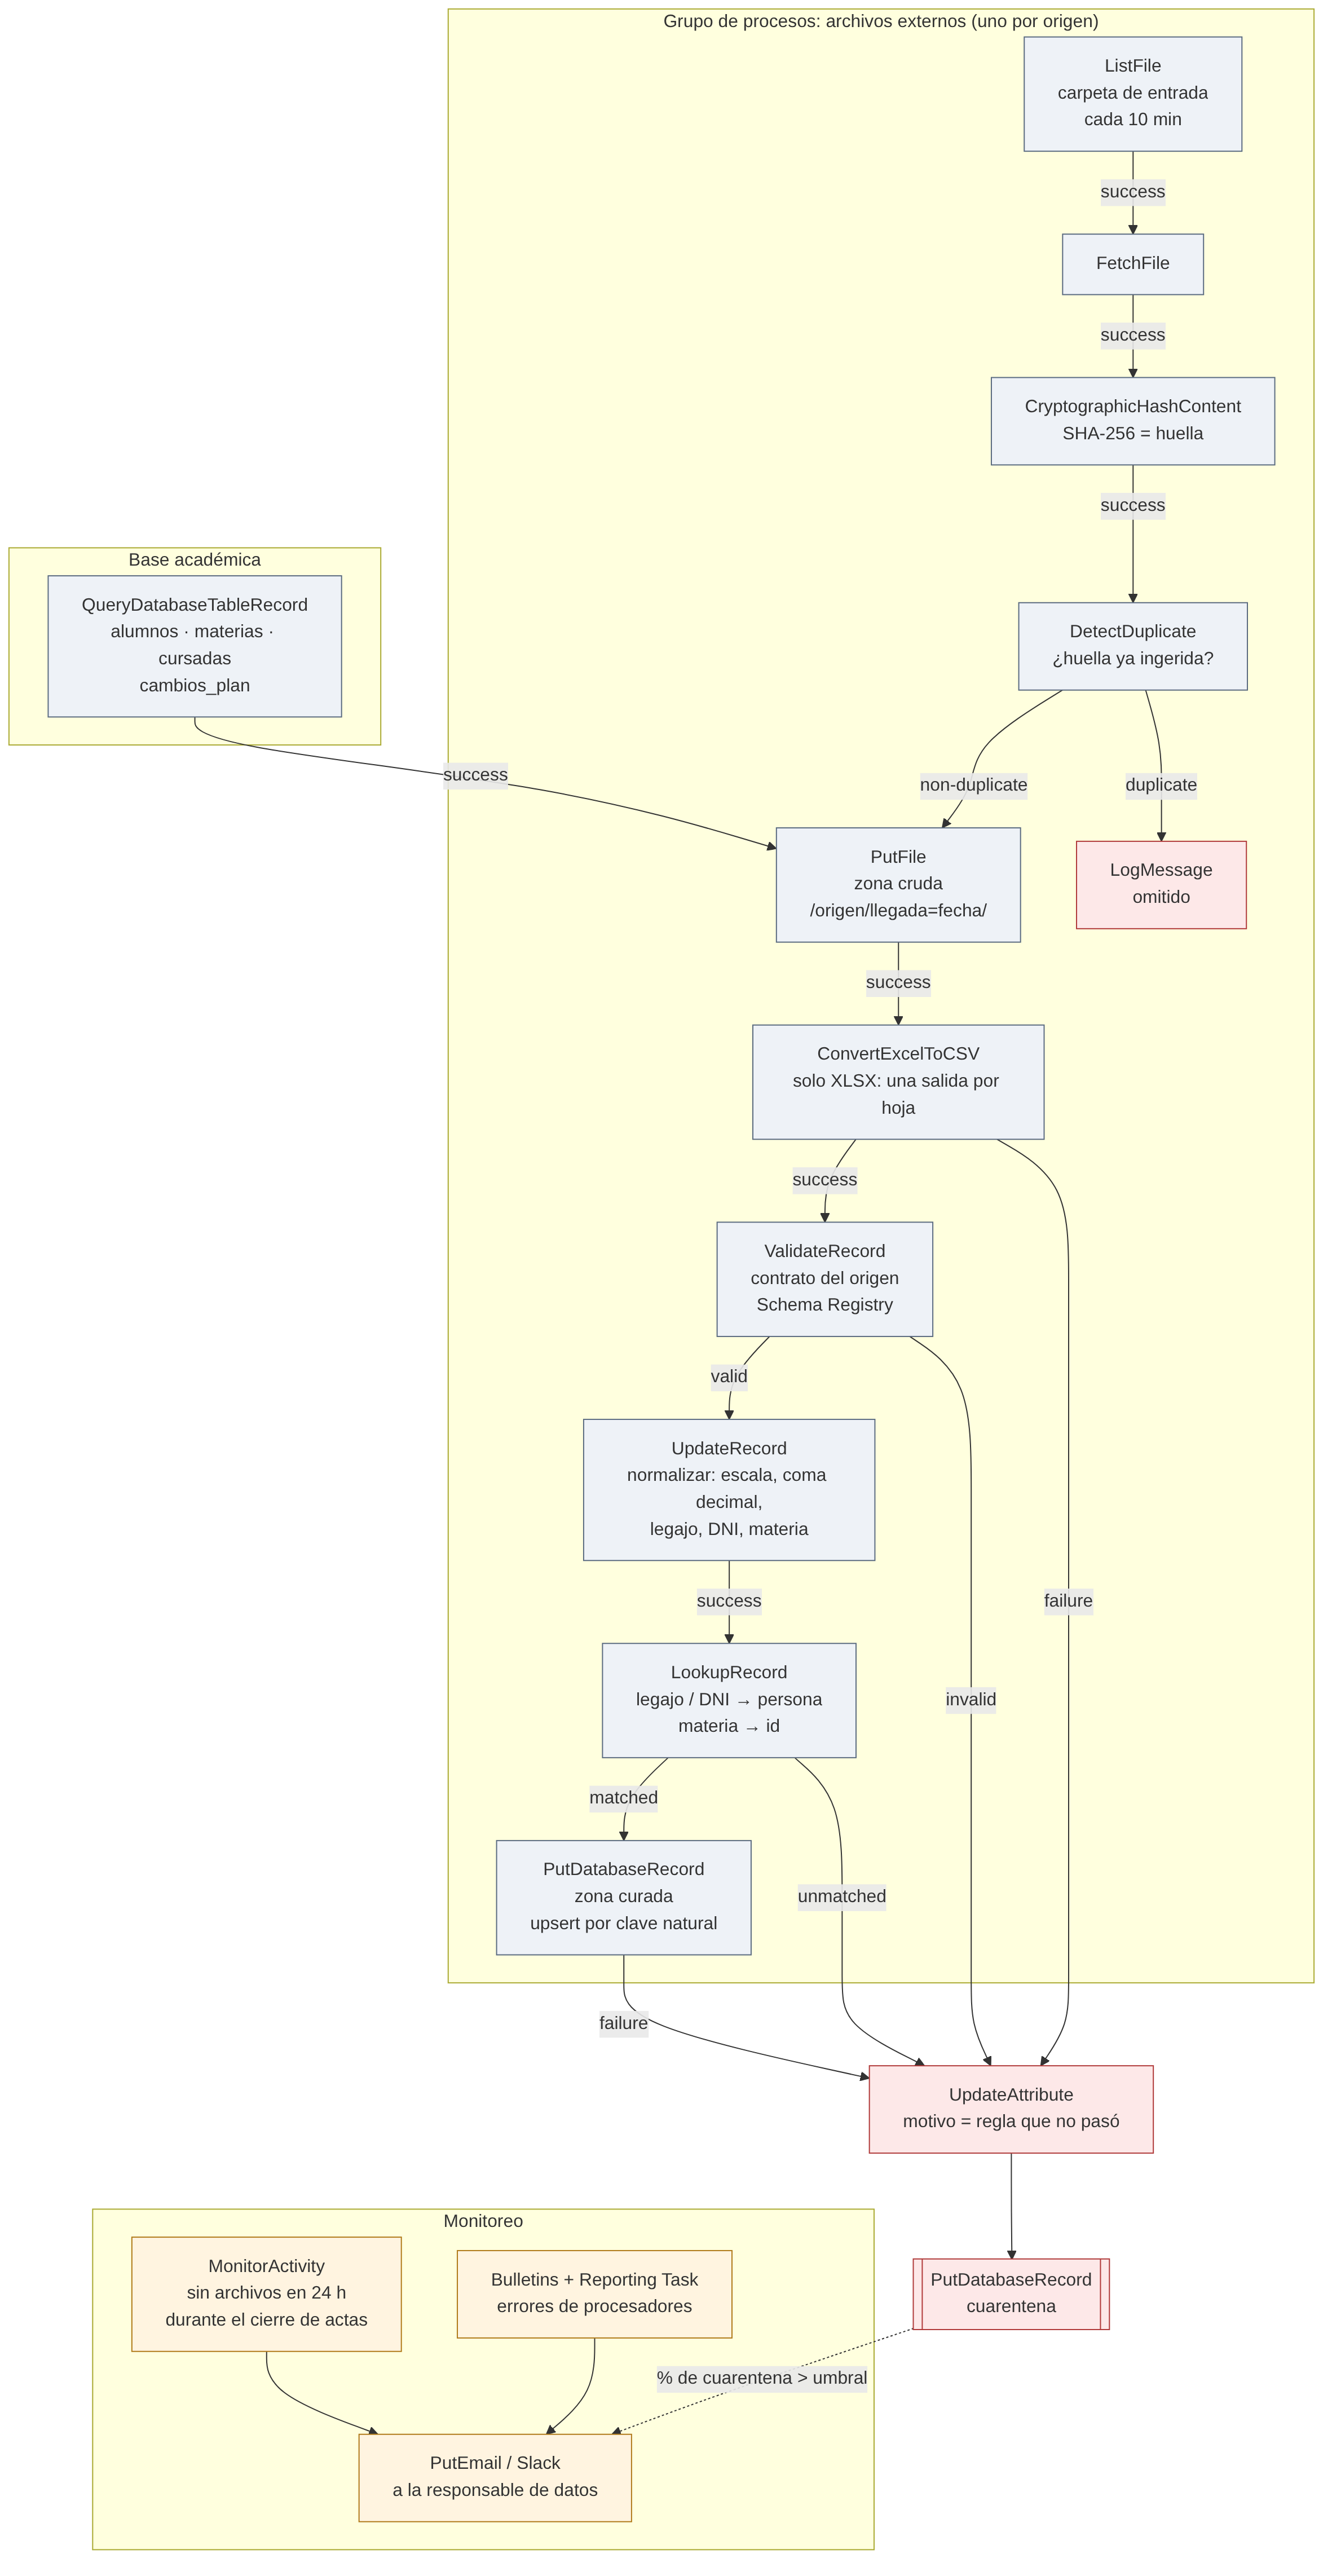

**El patrón es el mismo para los seis orígenes.** Cambia el contrato y la normalización de cada uno:
1. **Se lista y se toma el archivo**, y se le calcula una huella (SHA-256). Si esa huella ya se ingirió, se omite: reprocesar un archivo igual no hace nada.
2. **Se guarda tal cual en la zona cruda**, en una carpeta por fecha de llegada. Nunca se modifica.
3. **Se valida contra el contrato.**
   - Si se rompe la *forma* del archivo (columnas, hojas, encabezado), el archivo entero va a cuarentena y no entra ninguna fila.
   - Si fallan los *datos* de una fila (una nota fuera de rango, un DNI que no existe), va a cuarentena solo esa fila, con el motivo.
4. **Se normaliza y se cruza** con lo que ya está cargado: el legajo o el DNI pasan a persona, y el nombre de la materia a su id.
5. **Se carga en la zona curada** con un *upsert* por clave natural: si la fila ya existe se actualiza, y si no, se inserta. Todo el archivo entra en **una transacción**: o entra completo o no entra nada.
6. **Se controla el balance:** filas leídas = cargadas + cuarentena. Si no cierra, se revierte (es el control del módulo 1).

| Procesador en NiFi | En el script | Qué hace |
| --- | --- | --- |
| ListFile + FetchFile / QueryDatabaseTableRecord | `ingerir_todo()`, `extraer_base_academica()` | Toma cada origen; de la base académica saca una foto por tabla |
| CryptographicHashContent + DetectDuplicate | `huella()` y la consulta a `control_lote` | No reprocesa un archivo que ya entró igual |
| PutFile (zona cruda) | `shutil.copy2` a `lake/cruda/origen/llegada=fecha/` | Guarda el original tal cual |
| ConvertExcelToCSV | `pd.read_excel` hoja por hoja | Las actas traen una hoja por área |
| ValidateRecord + Schema Registry | `CONTRATO_*` y `exigir_columnas()` | La forma del archivo; si falla, `ContratoRoto` |
| UpdateRecord | la normalización de cada `procesar_*` | Escala, coma decimal, legajo, DNI, tildes |
| LookupRecord | `mapa()` y `cursada_de()` | Legajo o DNI → persona; materia → id; alumno + materia + cuatrimestre → cursada |
| relación *invalid* / *unmatched* / *failure* → PutDatabaseRecord | `filtrar()` y `a_cuarentena()` | Cada fila mala va a cuarentena con su motivo |
| PutDatabaseRecord | `INSERT ... ON CONFLICT DO UPDATE` | Upsert idempotente en la zona curada |
| MonitorActivity + Bulletins + PutEmail | `tablero_ingesta()` | Semáforo por origen y aviso a la responsable |

**Qué resuelve el contrato de cada origen** (los problemas son los del diagnóstico):

| Origen | Contrato y normalización | Va a cuarentena | Por qué reprocesar no duplica |
| --- | --- | --- | --- |
| Base académica | Personas y legajos: `cargar_dim_alumno` (módulo 3). Cursadas: el alumno se traduce a persona. | Cursadas de alumnos inexistentes (AL9xxxx) | Upsert por `id_cursada` |
| Biblioteca (JSONL) | Todo como texto, porque el ISBN no es un número. Si viene el legajo en vez del id, se traduce. Fecha y hora con formato fijo. | Alumno inexistente, ISBN inválido, fecha inválida | La clave es persona + ISBN + fecha y hora (`INSERT OR IGNORE`) |
| Notas (CSV) | **Dos versiones del contrato:** v1 (`id_alumno`, `nota`, escala 0–10) y v2 (`id_estudiante`, `calificacion`, escala 0–100). La escala sale del contrato, no de mirar los datos. El cuatrimestre sale del nombre del archivo. | Nota fuera de la escala, alumno o cursada inexistente | Upsert por `id_cursada`. **El CSV no pisa una nota que vino del acta.** |
| Actas (XLSX) | Título en A1, cuatrimestre en A2, encabezado en la fila 4. Al legajo se le agrega la «L» y se pasa a mayúscula. La coma decimal pasa a punto. «AUS» es ausente, sin nota. | Nota fuera de 0–10, legajo o materia inexistente | Upsert por `id_cursada`: el acta prevalece (supuesto S2) |
| Becas (CSV) | Al DNI se le sacan los puntos y se cruza contra `persona_pii`. Hay una lista cerrada de tipos de beca. | DNI que no es de ningún alumno, porcentaje o fecha inválidos | Upsert por persona + fecha desde |
| Encuesta (XLSX) | Título en A1 y encabezado en la fila 3. La materia se compara sin tildes («Matería» → «Materia»). | Puntaje fuera de 1–5, materia inexistente | Es anónima y no tiene clave: **se reemplaza la partición** (los cuatrimestres del archivo) |

| Campo | Contenido |
| --- | --- |
| Decisión | Validar contra un **contrato versionado** antes de cargar. Si se rompe la forma, el archivo entero va a cuarentena. Si fallan los datos de una fila, solo esa fila. |
| Restricción comprobable | Los archivos externos cambian de formato sin aviso: las notas de 2025-1c cambiaron de columnas y de escala. Además, hay errores de a una fila: 26 notas fuera de rango sobre 7.956. |
| Opción elegida y costo que se acepta | Contrato versionado más cuarentena en dos niveles. El costo: cada formato nuevo exige que alguien agregue una versión al contrato. Hasta que eso pase, ese archivo no se carga. |
| **Alternativa descartada y por qué** | **Inferir el esquema y la escala mirando los datos**, por ejemplo «si hay notas mayores a 10, la escala es 0–100». Un cuatrimestre con todas las notas bajas en escala 0–100 se cargaría como 0–10 sin que nadie se entere. También se descartó **rechazar el archivo entero por cualquier fila mala**: 26 notas fuera de rango frenarían 7.930 notas buenas. |
| Control que detecta el fallo y qué se hace cuando suena | El **semáforo del tablero de ingesta**. 🔴 si se rompió el contrato o no cerró el balance. 🟡 si más del 5 % de las filas fue a cuarentena. 🟢 si está todo bien. **Lo recibe la responsable de datos académicos.** Si es 🔴, actualiza el contrato o le pide al origen que reenvíe. Si es 🟡, revisa la cuarentena y decide: corregir y reprocesar, o aceptar y documentar. |

**Qué cambiaría la decisión:** si los orígenes publicaran su esquema en un registro compartido (Schema Registry), el contrato se tomaría de ahí y los cambios llegarían avisados.

### El marco común

Lo que se repite en todos los orígenes: huella, zona cruda, transacción, balance, cuarentena y registro del lote.

In [13]:
# ===== Marco común de ingestión: lo que en NiFi hacen ListFile, Hash, DetectDuplicate, PutFile y la cuarentena =====
import hashlib, unicodedata, datetime as dt

CRUDA = "lake/cruda"
zonas()                                            # crea lake/cruda, curada, variables y consumo

class ContratoRoto(Exception):
    """El archivo entero no cumple el contrato (columnas, hojas, encabezado): no se carga ninguna fila."""

def huella(ruta):
    return hashlib.sha256(open(ruta, "rb").read()).hexdigest()

def a_cuarentena(lote, fuente, filas, motivo):
    """Manda filas (un DataFrame) a cuarentena con su motivo. Devuelve cuántas mandó."""
    if len(filas) == 0:
        return 0
    registros = [(lote, fuente, json.dumps(f, ensure_ascii=False, default=str), motivo)
                 for f in filas.astype(object).where(filas.notna(), None).to_dict("records")]
    almacen.executemany("INSERT INTO cuarentena (id_lote, fuente, registro, motivo) VALUES (?, ?, ?, ?)", registros)
    return len(registros)

def ingerir(fuente, ruta, procesar, forzar=False):
    """Ingesta de un origen: huella → zona cruda → contrato y carga en una transacción → balance → registro del lote.
    procesar(ruta, lote) devuelve (leídas, cargadas, en_cuarentena, extra) o levanta ContratoRoto."""
    firma = huella(ruta)
    ya = uno("SELECT id_lote FROM control_lote WHERE fuente = ? AND huella = ? AND estado = 'ok'", (fuente, firma))
    if ya and not forzar:                                              # DetectDuplicate
        lote = abrir_lote("ingesta", fuente)
        almacen.execute("UPDATE control_lote SET huella = ? WHERE id_lote = ?", (firma, lote))
        cerrar_lote(lote, "omitido", detalle=f"mismo contenido que el lote {ya}: no se reprocesa")
        return {"fuente": fuente, "estado": "omitido", "detalle": f"igual al lote {ya}"}

    destino = os.path.join(CRUDA, fuente.split(".")[0], f"llegada={dt.date.today()}")
    os.makedirs(destino, exist_ok=True)
    shutil.copy2(ruta, destino)                                        # PutFile a la zona cruda, tal cual llegó

    lote = abrir_lote("ingesta", fuente)
    almacen.execute("UPDATE control_lote SET huella = ? WHERE id_lote = ?", (firma, lote))
    try:
        almacen.execute("BEGIN")
        leidas, cargadas, cuarentena, extra = procesar(ruta, lote)
        if leidas != cargadas + cuarentena:                            # el control del módulo 1
            raise CargaRechazada(f"balance: {leidas} leídas ≠ {cargadas} cargadas + {cuarentena} en cuarentena")
        almacen.execute("COMMIT")
        cerrar_lote(lote, "ok", leidas, cargadas, cuarentena, json.dumps(extra, ensure_ascii=False) if extra else None)
        return {"fuente": fuente, "estado": "ok", "leídas": leidas, "cargadas": cargadas, "cuarentena": cuarentena,
                "detalle": " · ".join(f"{k}: {v}" for k, v in (extra or {}).items())}
    except ContratoRoto as error:
        if almacen.in_transaction: almacen.execute("ROLLBACK")
        a_cuarentena(lote, fuente, pd.DataFrame([{"archivo": ruta, "huella": firma}]), f"contrato roto: {error}")
        cerrar_lote(lote, "falló", detalle=f"ContratoRoto: {error}")
        return {"fuente": fuente, "estado": "falló", "detalle": f"archivo entero a cuarentena: {error}"}
    except Exception as error:
        if almacen.in_transaction: almacen.execute("ROLLBACK")
        cerrar_lote(lote, "falló", detalle=f"{type(error).__name__}: {error}")
        return {"fuente": fuente, "estado": "falló", "detalle": f"{type(error).__name__}: {error}"}

def exigir_columnas(df, esperadas, donde):
    if list(df.columns) != list(esperadas):
        raise ContratoRoto(f"{donde}: columnas {list(df.columns)}, se esperaban {list(esperadas)}")

def sin_tildes(texto):
    return "".join(c for c in unicodedata.normalize("NFKD", str(texto)) if not unicodedata.combining(c))

def mapa(consulta):
    """Diccionario clave → valor desde el almacén (para los Lookup)."""
    return dict(almacen.execute(consulta).fetchall())

### Un procesador por origen

Cada uno declara su contrato arriba de todo, normaliza, cruza contra lo que ya está cargado y deja en cuarentena lo que no pasa.

In [14]:
# ===== Un procesador por origen: contrato, normalización, lookup y carga =====
# Cada uno devuelve (leídas, cargadas, en_cuarentena, extra). Las filas que no pasan van a cuarentena con su motivo.

# --- Contratos: lo que esperamos de cada origen. Si cambia, se cambia acá y queda versionado en el repo. ---
CONTRATO_NOTAS = {                  # columnas exactas por versión → cómo se llaman en el modelo y en qué escala vienen
    "v1": {"columnas": ["id_alumno", "id_materia", "nota", "docente"], "renombrar": {}, "escala": 10},
    "v2": {"columnas": ["id_estudiante", "id_materia", "calificacion", "docente"],
           "renombrar": {"id_estudiante": "id_alumno", "calificacion": "nota"}, "escala": 100},
}
CONTRATO_ACTAS = {"titulo": "Acta de calificaciones", "fila_encabezado": 3,
                  "columnas": ["Legajo", "Materia", "Docente", "Condición", "Nota"], "escala": 10}
CONTRATO_BECAS = {"columnas": ["dni", "tipo_beca", "porcentaje", "desde"], "tipos": {"Necesidad", "Mérito", "Deporte"}}
CONTRATO_ENCUESTA = {"titulo": "Encuesta de satisfacción", "fila_encabezado": 2,
                     "columnas": ["Materia", "Cuatrimestre", "Puntaje", "Comentario"], "escala": (1, 5)}
CUATRIMESTRE = r"^\d{4}-[12]c$"

def filtrar(df, reglas, lote, fuente, columnas):
    """Aplica las reglas en orden. Cada regla es (función que marca las filas malas, motivo).
    Las filas malas van a cuarentena con su motivo y salen del DataFrame. Devuelve (buenas, cuántas a cuarentena)."""
    q = 0
    for regla, motivo in reglas:
        malas = regla(df)
        q += a_cuarentena(lote, fuente, df[malas][columnas], motivo)
        df = df[~malas]
    return df, q

def extraer_base_academica():
    """QueryDatabaseTableRecord: saca una foto de cada tabla de la base académica a un CSV de entrada."""
    carpeta = "lake/entrada/base_academica"; os.makedirs(carpeta, exist_ok=True)
    for tabla in ("alumnos", "materias", "cursadas", "cambios_plan"):
        sql(f"SELECT * FROM {tabla}").to_csv(f"{carpeta}/{tabla}.csv", index=False)
    return carpeta

def procesar_materias(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, ["id_materia", "nombre", "carrera"], "materias")
    malas = df[df.id_materia.isna() | df.nombre.isna() | df.duplicated("id_materia", keep=False)]
    q = a_cuarentena(lote, "base_academica.materias", malas, "materia sin id/nombre o id repetido")
    buenas = df.drop(malas.index)
    almacen.executemany("""INSERT INTO materia VALUES (?, ?, ?) ON CONFLICT (id_materia) DO UPDATE
                           SET nombre = excluded.nombre, carrera = excluded.carrera""", buenas.values.tolist())
    return len(df), len(buenas), q, None

def procesar_cursadas(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, ["id_cursada", "id_alumno", "id_materia", "cuatrimestre", "estado"], "cursadas")
    persona = mapa("SELECT id_alumno, id_persona FROM legajo")
    df["id_persona"] = df.id_alumno.map(persona)
    df, q = filtrar(df, [
        (lambda d: d.id_persona.isna(), "alumno inexistente en la base académica"),
        (lambda d: ~d.id_materia.isin(list(mapa("SELECT id_materia, 1 FROM materia"))), "materia inexistente"),
        (lambda d: ~d.cuatrimestre.str.match(CUATRIMESTRE, na=False), "cuatrimestre con formato inválido"),
        (lambda d: ~d.estado.isin(["aprobada", "desaprobada", "abandonó"]), "estado desconocido"),
    ], lote, "base_academica.cursadas", ["id_cursada", "id_alumno", "id_materia", "cuatrimestre", "estado"])
    rep = df.duplicated(["id_persona", "id_materia", "cuatrimestre"], keep="first")
    q += a_cuarentena(lote, "base_academica.cursadas", df[rep].drop(columns="id_persona"), "misma persona, materia y cuatrimestre repetida")
    df = df[~rep]
    almacen.executemany("""INSERT INTO cursada (id_cursada, id_persona, id_materia, cuatrimestre, estado) VALUES (?, ?, ?, ?, ?)
                           ON CONFLICT (id_cursada) DO UPDATE SET estado = excluded.estado""",
                        df[["id_cursada", "id_persona", "id_materia", "cuatrimestre", "estado"]].values.tolist())
    return len(pd.read_csv(ruta)), len(df), q, None

def procesar_biblioteca(ruta, lote):
    filas = [json.loads(l) for l in open(ruta, encoding="utf-8") if l.strip()]
    df = pd.DataFrame(filas, dtype=str)                       # todo como texto: el ISBN no es un número
    exigir_columnas(df[sorted(df.columns)], ["id_alumno", "isbn", "tipo", "ts"], "biblioteca")
    por_id, por_legajo = mapa("SELECT id_alumno, id_persona FROM legajo"), mapa("SELECT legajo, id_persona FROM legajo")
    df["id_persona"] = df.id_alumno.map(por_id).fillna(df.id_alumno.str.upper().map(por_legajo))   # a veces viene el legajo
    df["ts_ok"] = pd.to_datetime(df.ts, errors="coerce", format="%Y-%m-%dT%H:%M:%S")
    df, q = filtrar(df, [(lambda d: d.id_persona.isna(), "alumno o legajo inexistente"),
                         (lambda d: ~d.isbn.str.fullmatch(r"\d{13}", na=False), "ISBN inválido"),
                         (lambda d: d.ts_ok.isna(), "fecha y hora inválida"),
                         (lambda d: d.tipo != "prestamo", "tipo de evento desconocido")],
                    lote, "biblioteca", ["id_alumno", "isbn", "ts", "tipo"])
    antes = uno("SELECT COUNT(*) FROM prestamo")
    almacen.executemany("INSERT OR IGNORE INTO prestamo (id_persona, isbn, ts, id_lote) VALUES (?, ?, ?, ?)",
                        [(p, i, t, lote) for p, i, t in df[["id_persona", "isbn", "ts"]].values])
    nuevos = uno("SELECT COUNT(*) FROM prestamo") - antes
    return len(filas), len(df), q, {"nuevos": nuevos, "ya estaban": len(df) - nuevos,
                                    "por legajo": int(df.id_alumno.str.upper().str.startswith("L").sum())}

def cursada_de(df, cuatrimestre):
    """Lookup: (persona, materia, cuatrimestre) → id_cursada."""
    c = pd.read_sql_query("SELECT id_persona, id_materia, id_cursada FROM cursada WHERE cuatrimestre = ?", almacen, params=(cuatrimestre,))
    return df.merge(c, on=["id_persona", "id_materia"], how="left")

def procesar_notas(ruta, lote):
    cuatrimestre = re.search(r"notas_(\d{4}-[12]c)\.csv$", ruta)
    if not cuatrimestre: raise ContratoRoto(f"el nombre {os.path.basename(ruta)} no dice el cuatrimestre")
    cuatrimestre = cuatrimestre.group(1)
    df = pd.read_csv(ruta, dtype=str)
    version = next((v for v, c in CONTRATO_NOTAS.items() if list(df.columns) == c["columnas"]), None)
    if version is None:                                       # cambio de esquema que no conocemos: no se adivina
        raise ContratoRoto(f"columnas {list(df.columns)} no coinciden con ninguna versión del contrato {list(CONTRATO_NOTAS)}")
    c = CONTRATO_NOTAS[version]
    df = df.rename(columns=c["renombrar"])
    df["nota_num"] = pd.to_numeric(df.nota, errors="coerce")
    df["id_persona"] = df.id_alumno.map(mapa("SELECT id_alumno, id_persona FROM legajo"))
    df = cursada_de(df, cuatrimestre)
    df, q = filtrar(df, [(lambda d: d.nota_num.isna(), "nota no numérica"),
                         (lambda d: ~d.nota_num.between(0, c["escala"]), f"nota fuera de rango (0 a {c['escala']})"),
                         (lambda d: d.id_persona.isna(), "alumno inexistente"),
                         (lambda d: d.id_cursada.isna(), f"no hay cursada de ese alumno y materia en {cuatrimestre}")],
                    lote, f"notas_{cuatrimestre}", ["id_alumno", "id_materia", "nota", "docente"])
    df["nota_10"] = (df.nota_num * 10 / c["escala"]).round(2)  # normalizada a 0–10 según el contrato, no según los datos
    # El CSV no pisa una nota que ya vino del acta (el acta es la fuente de verdad, supuesto S2).
    almacen.executemany("""INSERT INTO nota (id_cursada, nota, ausente, docente, fuente_nota, id_lote) VALUES (?, ?, 0, ?, 'csv', ?)
                           ON CONFLICT (id_cursada) DO UPDATE SET nota = excluded.nota, docente = excluded.docente,
                           id_lote = excluded.id_lote WHERE nota.fuente_nota = 'csv'""",
                        [(i, n, d, lote) for i, n, d in df[["id_cursada", "nota_10", "docente"]].values])
    return len(pd.read_csv(ruta)), len(df), q, {"versión del contrato": version, "escala": c["escala"]}

def procesar_actas(ruta, lote):
    libro = pd.ExcelFile(ruta); leidas = cargadas = q = 0; difieren = ausentes = 0
    materia = mapa("SELECT nombre, id_materia FROM materia"); legajo = mapa("SELECT legajo, id_persona FROM legajo")
    for hoja in libro.sheet_names:                                   # ConvertExcelToCSV: una salida por hoja
        cabecera = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=2)
        titulo, cuat = str(cabecera.iloc[0, 0]), re.search(r"(\d{4}-[12]c)", str(cabecera.iloc[1, 0]))
        if not titulo.startswith(CONTRATO_ACTAS["titulo"]) or not cuat:
            raise ContratoRoto(f"hoja «{hoja}»: no tiene el título o el cuatrimestre en A1/A2")
        df = pd.read_excel(ruta, sheet_name=hoja, header=CONTRATO_ACTAS["fila_encabezado"], dtype=str)
        exigir_columnas(df, CONTRATO_ACTAS["columnas"], f"hoja «{hoja}»")
        leidas += len(df); cuat = cuat.group(1)
        leg = df.Legajo.str.strip().str.upper()
        df["legajo_n"] = leg.where(leg.str.startswith("L"), "L" + leg)              # «21464» y «l20849» → «L21464», «L20849»
        df["ausente"] = (df.Nota.str.strip().str.upper() == "AUS").astype(int)
        df["nota_num"] = pd.to_numeric(df.Nota.str.replace(",", ".", regex=False), errors="coerce")   # «7,0» → 7.0
        df["id_persona"], df["id_materia"] = df.legajo_n.map(legajo), df.Materia.map(materia)
        df = cursada_de(df, cuat)
        df, malas = filtrar(df, [(lambda d: (d.ausente == 0) & d.nota_num.isna(), "nota no numérica"),
                                 (lambda d: (d.ausente == 0) & ~d.nota_num.between(0, 10), "nota fuera de rango (0 a 10)"),
                                 (lambda d: d.id_persona.isna(), "legajo inexistente"),
                                 (lambda d: d.id_materia.isna(), "materia inexistente"),
                                 (lambda d: d.id_cursada.isna(), f"no hay cursada de ese alumno y materia en {cuat}")],
                            lote, f"actas_docentes.{hoja}", CONTRATO_ACTAS["columnas"])
        q += malas
        # Control cruzado con el CSV: ¿el acta dice lo mismo que la nota que ya teníamos?
        previa = pd.read_sql_query("SELECT id_cursada, nota AS nota_csv FROM nota WHERE fuente_nota = 'csv'", almacen)
        cruce = df.merge(previa, on="id_cursada")
        difieren += int(((cruce.ausente == 1) | ((cruce.nota_num - cruce.nota_csv).abs() > 0.001)).sum())
        ausentes += int(df.ausente.sum())
        almacen.executemany("""INSERT INTO nota (id_cursada, nota, ausente, docente, condicion, fuente_nota, id_lote)
                               VALUES (?, ?, ?, ?, ?, 'acta', ?)
                               ON CONFLICT (id_cursada) DO UPDATE SET nota = excluded.nota, ausente = excluded.ausente,
                               docente = excluded.docente, condicion = excluded.condicion, fuente_nota = 'acta', id_lote = excluded.id_lote""",
                            [(i, None if a else n, int(a), d, cond, lote)
                             for i, n, a, d, cond in df[["id_cursada", "nota_num", "ausente", "Docente", "Condición"]].values])
        cargadas += len(df)
    return leidas, cargadas, q, {"ausentes": ausentes, "difieren del CSV": difieren}

def procesar_becas(ruta, lote):
    df = pd.read_csv(ruta, dtype=str)
    exigir_columnas(df, CONTRATO_BECAS["columnas"], "becas")
    df["dni_n"] = df.dni.str.replace(".", "", regex=False).str.strip()          # «35.527.738» → «35527738»
    df["id_persona"] = df.dni_n.map(mapa("SELECT dni, id_persona FROM persona_pii"))
    df["pct"] = pd.to_numeric(df.porcentaje, errors="coerce")
    df, q = filtrar(df, [(lambda d: ~d.dni_n.str.fullmatch(r"\d{8}", na=False), "DNI inválido"),
                         (lambda d: d.id_persona.isna(), "DNI que no es de ningún alumno"),
                         (lambda d: ~d.pct.between(1, 100), "porcentaje fuera de 1 a 100"),
                         (lambda d: pd.to_datetime(d.desde, errors="coerce", format="%Y-%m-%d").isna(), "fecha inválida"),
                         (lambda d: ~d.tipo_beca.isin(CONTRATO_BECAS["tipos"]), "tipo de beca desconocido")],
                    lote, "becas", CONTRATO_BECAS["columnas"])
    almacen.executemany("""INSERT INTO beca VALUES (?, ?, ?, ?) ON CONFLICT (id_persona, desde)
                           DO UPDATE SET tipo_beca = excluded.tipo_beca, porcentaje = excluded.porcentaje""",
                        [(p, t, int(x), d) for p, t, x, d in df[["id_persona", "tipo_beca", "pct", "desde"]].values])
    return len(pd.read_csv(ruta)), len(df), q, {"DNI con puntos": int(pd.read_csv(ruta, dtype=str).dni.str.contains(r"\.").sum())}

def procesar_encuesta(ruta, lote):
    titulo = str(pd.read_excel(ruta, header=None, nrows=1).iloc[0, 0])
    if not titulo.startswith(CONTRATO_ENCUESTA["titulo"]): raise ContratoRoto("no tiene el título esperado en A1")
    df = pd.read_excel(ruta, header=CONTRATO_ENCUESTA["fila_encabezado"], dtype=str)
    exigir_columnas(df, CONTRATO_ENCUESTA["columnas"], "encuesta")
    materia = {sin_tildes(k): v for k, v in mapa("SELECT nombre, id_materia FROM materia").items()}
    df["id_materia"] = df.Materia.map(lambda m: materia.get(sin_tildes(m)))             # «Matería 11» → MT011
    df["puntaje"] = pd.to_numeric(df.Puntaje, errors="coerce")
    lo, hi = CONTRATO_ENCUESTA["escala"]
    df, q = filtrar(df, [(lambda d: d.id_materia.isna(), "materia inexistente"),
                         (lambda d: ~d.Cuatrimestre.str.match(CUATRIMESTRE, na=False), "cuatrimestre inválido"),
                         (lambda d: ~d.puntaje.between(lo, hi), f"puntaje fuera de {lo} a {hi}")],
                    lote, "encuesta", CONTRATO_ENCUESTA["columnas"])
    # Es anónima: no hay clave natural. Se reemplaza la partición (los cuatrimestres del archivo) entera: reprocesar no duplica.
    for cuat in df.Cuatrimestre.unique():
        almacen.execute("DELETE FROM respuesta_encuesta WHERE cuatrimestre = ?", (cuat,))
    almacen.executemany("INSERT INTO respuesta_encuesta (id_materia, cuatrimestre, puntaje, comentario) VALUES (?, ?, ?, ?)",
                        [(m, c, int(p), None if pd.isna(t) else t) for m, c, p, t in df[["id_materia", "Cuatrimestre", "puntaje", "Comentario"]].values])
    return len(pd.read_excel(ruta, header=CONTRATO_ENCUESTA["fila_encabezado"])), len(df), q, \
           {"materia corregida (tilde)": int((df.Materia != df.Materia.map(sin_tildes)).sum())}

### Correr la ingestión

In [15]:
# El flujo completo, en el orden en que dependen unos de otros:
# primero la base académica (personas, materias, cursadas) porque todo lo demás se cruza contra ella.
# Las personas y los legajos ya los cargó cargar_dim_alumno (módulo 3), que es el paso de «alumnos + cambios_plan».
def ingerir_todo(forzar=False):
    base = extraer_base_academica()
    E = EXTERNOS
    pasos = [("base_academica.materias", f"{base}/materias.csv",           procesar_materias),
             ("base_academica.cursadas", f"{base}/cursadas.csv",           procesar_cursadas),
             ("biblioteca",              f"{DESTINO}/eventos/biblioteca.jsonl", procesar_biblioteca),
             ("notas_2024-2c",           f"{E}/notas_2024-2c.csv",         procesar_notas),
             ("notas_2025-1c",           f"{E}/notas_2025-1c.csv",         procesar_notas),
             ("actas_docentes",          f"{E}/actas_docentes.xlsx",       procesar_actas),   # después de las notas: el acta prevalece
             ("becas",                   f"{E}/becas.csv",                 procesar_becas),
             ("encuesta",                f"{E}/encuesta_satisfaccion.xlsx", procesar_encuesta)]
    return pd.DataFrame([ingerir(fuente, ruta, procesar, forzar) for fuente, ruta, procesar in pasos])

ingesta = ingerir_todo()
ingesta

,fuente,estado,leídas,cargadas,cuarentena,detalle
0,base_academica.materias,ok,40,40,0,
1,base_academica.cursadas,ok,15315,15290,25,
2,biblioteca,ok,10946,10946,0,nuevos: 10946 · ya estaban: 0 · por legajo: 1126
3,notas_2024-2c,ok,7956,7930,26,versión del contrato: v1 · escala: 10
4,notas_2025-1c,ok,7334,7302,32,versión del contrato: v2 · escala: 100
5,actas_docentes,ok,1500,1490,10,ausentes: 45 · difieren del CSV: 45
6,becas,ok,320,300,20,DNI con puntos: 94
7,encuesta,ok,800,785,15,materia corregida (tilde): 44


### Monitoreo

In [16]:
# Monitoreo: el último lote de cada origen, con su balance y un semáforo.
UMBRAL_CUARENTENA = 0.05     # más de 5 % de filas en cuarentena es una alerta: algo cambió en el origen

def tablero_ingesta():
    t = sql("""SELECT fuente, id_lote, estado, filas_leidas, filas_cargadas, filas_cuarentena, detalle
               FROM control_lote WHERE proceso = 'ingesta'
                 AND id_lote IN (SELECT MAX(id_lote) FROM control_lote WHERE proceso = 'ingesta' AND estado <> 'omitido' GROUP BY fuente)
               ORDER BY id_lote""", base="dwh.db")
    t["% cuarentena"] = (100 * t.filas_cuarentena / t.filas_leidas).round(1)
    t["balance"] = (t.filas_leidas == t.filas_cargadas + t.filas_cuarentena).map({True: "cierra", False: "NO cierra"})
    t["semáforo"] = [ "🔴 falló" if e == "falló" else ("🟡 revisar" if p > 100 * UMBRAL_CUARENTENA else "🟢 ok")
                      for e, p in zip(t.estado, t["% cuarentena"].fillna(0))]
    return t.astype({"filas_leidas": "Int64", "filas_cargadas": "Int64", "filas_cuarentena": "Int64"})

display(tablero_ingesta().drop(columns="detalle"))
print("Qué hay en cuarentena y por qué:")
sql("""SELECT fuente, motivo, COUNT(*) AS filas FROM cuarentena
       WHERE id_lote IN (SELECT MAX(id_lote) FROM control_lote WHERE proceso = 'ingesta' AND estado <> 'omitido' GROUP BY fuente)
       GROUP BY fuente, motivo ORDER BY fuente, filas DESC""", base="dwh.db")

,fuente,id_lote,estado,filas_leidas,filas_cargadas,filas_cuarentena,% cuarentena,balance,semáforo
0,base_academica.materias,5,ok,40,40,0,0.000,cierra,🟢 ok
1,base_academica.cursadas,6,ok,15315,15290,25,0.200,cierra,🟢 ok
2,biblioteca,7,ok,10946,10946,0,0.000,cierra,🟢 ok
3,notas_2024-2c,8,ok,7956,7930,26,0.300,cierra,🟢 ok
4,notas_2025-1c,9,ok,7334,7302,32,0.400,cierra,🟢 ok
5,actas_docentes,10,ok,1500,1490,10,0.700,cierra,🟢 ok
6,becas,11,ok,320,300,20,6.200,cierra,🟡 revisar
7,encuesta,12,ok,800,785,15,1.900,cierra,🟢 ok


Qué hay en cuarentena y por qué:


,fuente,motivo,filas
0,actas_docentes.Ciencias,nota fuera de rango (0 a 10),5
1,actas_docentes.Gestión,nota fuera de rango (0 a 10),1
2,actas_docentes.Humanidades,nota fuera de rango (0 a 10),4
3,base_academica.cursadas,alumno inexistente en la base académica,25
4,becas,DNI que no es de ningún alumno,20
5,encuesta,puntaje fuera de 1 a 5,15
6,notas_2024-2c,nota fuera de rango (0 a 10),26
7,notas_2025-1c,nota fuera de rango (0 a 100),32


**Qué muestra la ingestión:**
- **Todos los orígenes cierran el balance.** Cada fila leída está cargada o en cuarentena con su motivo: no se pierde ninguna.
- **Lo que fue a cuarentena coincide con el diagnóstico:**
  - las notas fuera de rango de los dos CSV y de las actas;
  - las 25 cursadas de alumnos inexistentes;
  - los 20 DNI de becas que no son de ningún alumno;
  - los 15 puntajes de encuesta fuera de escala.
- **Los problemas que tenían arreglo se arreglaron sin cuarentena:**
  - los 1.126 préstamos identificados por legajo;
  - los legajos sin «L» de las actas y los 45 ausentes;
  - los 94 DNI con puntos;
  - las 44 respuestas válidas con «Matería».
- **Becas queda en 🟡:** el 6,2 % de las filas fue a cuarentena. Es el caso que el semáforo tiene que mostrar. ¿Son becas de personas que todavía no se inscribieron, o un error del área de becas? El caso no lo dice: lo decide la responsable de datos académicos, no la carga.
- **En los 45 ausentes, el acta y el CSV no coinciden:** el CSV trae una nota donde el acta dice «AUS». Vale el acta (supuesto S2), y la diferencia queda registrada en el lote para revisarla.

### Pruebas de los casos difíciles

1. **Idempotencia:** con los mismos archivos, una segunda corrida no hace nada.
2. **Reproceso forzado:** aunque se recargue todo, no se duplica ninguna fila y el CSV no pisa las notas del acta.
3. **Cambio de esquema sin aviso:** llega un archivo de notas con columnas que ninguna versión del contrato conoce.

In [17]:
# Prueba 1 · Idempotencia: correr todo otra vez. Como los archivos no cambiaron, cada origen se omite.
print("1) Segunda corrida con los mismos archivos:")
display(ingerir_todo()[["fuente", "estado", "detalle"]])

# Prueba 2 · Reproceso forzado: aunque se vuelva a cargar todo, no se duplica nada
#           y el CSV no pisa las notas que vinieron del acta.
foto = lambda: {t: uno(f"SELECT COUNT(*) FROM {t}") for t in ("cursada", "nota", "prestamo", "beca", "respuesta_encuesta")} | \
               {"notas del acta": uno("SELECT COUNT(*) FROM nota WHERE fuente_nota = 'acta'")}
antes = foto(); ingerir_todo(forzar=True); despues = foto()
print("2) Reproceso forzado de todos los orígenes:")
display(pd.DataFrame({"antes": antes, "después": despues}).assign(igual=lambda d: d.antes == d.después))

# Prueba 3 · Cambio de esquema sin aviso: llega un archivo de notas con columnas nuevas.
#           No se adivina: el archivo entero va a cuarentena y no entra ninguna fila.
os.makedirs("lake/pruebas", exist_ok=True)
nuevo = leer_externo("notas_2025-1c.csv").rename(columns={"id_estudiante": "legajo", "calificacion": "nota_final"}).head(50)
nuevo.to_csv("lake/pruebas/notas_2025-2c.csv", index=False)
notas_antes = uno("SELECT COUNT(*) FROM nota")
r = ingerir("notas_2025-2c", "lake/pruebas/notas_2025-2c.csv", procesar_notas)
print("3) Archivo con columnas nuevas →", r["estado"], "·", r["detalle"])
print(f"   Notas antes / después: {notas_antes} / {uno('SELECT COUNT(*) FROM nota')} · "
      f"en cuarentena: {uno('SELECT COUNT(*) FROM cuarentena WHERE fuente = ?', ('notas_2025-2c',))} registro (el archivo)")

1) Segunda corrida con los mismos archivos:


,fuente,estado,detalle
0,base_academica.materias,omitido,igual al lote 5
1,base_academica.cursadas,omitido,igual al lote 6
2,biblioteca,omitido,igual al lote 7
3,notas_2024-2c,omitido,igual al lote 8
4,notas_2025-1c,omitido,igual al lote 9
5,actas_docentes,omitido,igual al lote 10
6,becas,omitido,igual al lote 11
7,encuesta,omitido,igual al lote 12


2) Reproceso forzado de todos los orígenes:


,antes,después,igual
cursada,15290,15290,True
nota,15232,15232,True
prestamo,10946,10946,True
beca,300,300,True
respuesta_encuesta,785,785,True
notas del acta,1490,1490,True


3) Archivo con columnas nuevas → falló · archivo entero a cuarentena: columnas ['legajo', 'id_materia', 'nota_final', 'docente'] no coinciden con ninguna versión del contrato ['v1', 'v2']
   Notas antes / después: 15232 / 15232 · en cuarentena: 1 registro (el archivo)


## 5 · Orquestación

Un DAG con dependencias, calendario (diario durante el cierre de actas y semanal el resto del año), reintentos e idempotencia, y la decisión sobre los datos que llegan tarde. Con `correr_dag(tareas, dependencias)` lo ejecutás en este notebook.

In [18]:
def extraer(): pass
def transformar(): pass
def cargar_dwh(): pass

# estados = correr_dag({"extraer": extraer, "transformar": transformar, "cargar": cargar_dwh},
#                      {"transformar": ["extraer"], "cargar": ["transformar"]})

## 6 · Governance

Al menos **cinco reglas de calidad medibles** aplicadas a los datos propios y externos, con sus resultados, más los roles (dueño y responsable) y un contrato de datos. «No hay nulos» no alcanza como definición de calidad.

In [19]:
# regla("nombre", valor_medido, umbral)

In [20]:
pd.DataFrame(resultados_calidad)

""


## 7 · MLOps

Un modelo de riesgo de abandono: ficha de versión, criterios de promoción, monitoreo y marcha atrás, cuidando que no use información posterior al evento.

In [21]:
# Ficha de versión, criterios de promoción, monitoreo y marcha atrás (si corresponde)

## 8 · Plataformas

Las zonas de datos (cruda, curada, variables y consumo) con sus reglas de paso. Si hay un modelo, la arquitectura para Machine Learning.

In [22]:
zonas()

['consumo', 'cruda', 'curada', 'entrada', 'pruebas', 'variables']

## 9 · Seguridad y metadatos

Clasificación de los datos (DNI, nombre, fecha de nacimiento, correo y legajo), enmascaramiento y accesos por rol, y un catálogo mínimo con el linaje de un indicador.

In [23]:
clasificacion = {
    # "tabla.columna": "público | interno | confidencial | sensible",
}
catalogo = {
    # "indicador": {"dueño": "", "responsable": "", "definición": "", "frescura": "", "linaje": []},
}

## 10 · Proyecto: riesgos, backlog y defensa

**Matriz de riesgos**

| Riesgo | Probabilidad | Impacto | Cómo se detecta | Cómo se contiene y se recupera | Responsable |
| --- | --- | --- | --- | --- | --- |
|  |  |  |  |  |  |

**Backlog priorizado**

| Prioridad | Qué | Por qué ahora | Esfuerzo | Depende de |
| --- | --- | --- | --- | --- |
|  |  |  |  |  |

**Guion de la defensa de 8 minutos:** problema y decisión (1) · diseño (3) · evidencia (2) · fallas y recuperación (1) · lo que queda abierto (1).

### Antes de entregar

- [ ] Reinicié el kernel y corrí todo el notebook de punta a punta.
- [ ] Escribí qué suponemos y el caso no declara.
- [ ] Elegimos la herramienta después de fijar el requisito.
- [ ] Cada decisión tiene una alternativa descartada y el costo que aceptamos.
- [ ] Encontramos los problemas de las fuentes propias y externas y dijimos qué hacemos con cada uno.
- [ ] Cada control dice **qué se hace cuando falla** y quién decide.
- [ ] La carga es idempotente y se puede reprocesar un día cualquiera.
- [ ] Los datos sensibles están clasificados, enmascarados y con acceso por rol.
- [ ] Si el caso lleva un modelo, no usa información posterior al evento.
- [ ] Ensayamos la defensa en 8 minutos.